In [1]:
from pathlib import Path
import os, sys, re, json, hashlib, warnings, platform, importlib.metadata as metadata
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, hamming_loss
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBRegressor
SEED=552
np.random.seed(SEED)
thread_limit = threadpool_limits(limits=1)
ROOT=Path.cwd()
DATA=ROOT/'Homework 5 Data'
assert (DATA/'diagnosis.data').exists(), 'Run from the project root.'
for folder in ['results','figures']: (ROOT/folder).mkdir(exist_ok=True)
report=[]
def record_text(text): report.append({'kind':'text','text':text})
def say(text):
    display(Markdown(text)); record_text(text)
def table(df, name, report_include=True):
    df.to_csv(ROOT/'results'/f'{name}.csv',index=False)
    display(df)
    if report_include:
        report.append({'kind':'table','name':name,'columns':list(df.columns),
                       'rows':[[str(v) for v in row] for row in df.to_numpy().tolist()]})
def figure(fig, name, caption):
    fig.savefig(ROOT/'figures'/f'{name}.png',dpi=180,bbox_inches='tight')
    fig.savefig(ROOT/'figures'/f'{name}.pdf',bbox_inches='tight')
    plt.show(); plt.close(fig)
    report.append({'kind':'figure','path':f'figures/{name}.png','caption':caption})
sns.set_theme(style='whitegrid',context='notebook')
pd.set_option('display.max_rows',150)
pd.set_option('display.max_colwidth',100)
pd.set_option('display.precision',8)

# DSCI 552 Homework 5
**jay-zhao1**

## AI Usage Disclosure
I used AI tools to help me learn the relevant programming techniques and machine learning concepts, understand code implementations, and assist with debugging.

## Requirements and experimental protocol
The two-page assignment and all five footnotes were read, as were both supplied .names files and the supplied KDnuggets article. Local data are used without downloading replacements. The original question order is retained: 1(a) data, 1(b) full tree, 1(c) all rules, 1(d) pruning; 2(a) ordered split, 2(b) imputation, 2(c) correlations, 2(d) CV, 2(e) 11 feature plots, 2(f) OLS, 2(g) Ridge, 2(h) both LASSOs, 2(i) PCR, 2(j) XGBoost.

Seed 552 is fixed. All regression models retain all 122 predictive variables as candidate inputs; the 11-variable CV ranking is descriptive only. Regression tuning uses the same shuffled five-fold KFold within the training portion, minimizing validation MSE. The mandated external split is never shuffled. Imputation, scaling and PCA are fitted separately in each training fold through Pipeline. The test set is evaluated once per final fitted model, after all six models are frozen. No test metric is used to revise a model.

In [2]:
record_text('# DSCI 552 Homework 5\n**jay-zhao1**\n\n## AI Usage Disclosure\nI used AI tools to help me learn the relevant programming techniques and machine learning concepts, understand code implementations, and assist with debugging.\n\n## Requirements and experimental protocol\nThe two-page assignment and all five footnotes were read, as were both supplied .names files and the supplied KDnuggets article. Local data are used without downloading replacements. The original question order is retained: 1(a) data, 1(b) full tree, 1(c) all rules, 1(d) pruning; 2(a) ordered split, 2(b) imputation, 2(c) correlations, 2(d) CV, 2(e) 11 feature plots, 2(f) OLS, 2(g) Ridge, 2(h) both LASSOs, 2(i) PCR, 2(j) XGBoost.\n\nSeed 552 is fixed. All regression models retain all 122 predictive variables as candidate inputs; the 11-variable CV ranking is descriptive only. Regression tuning uses the same shuffled five-fold KFold within the training portion, minimizing validation MSE. The mandated external split is never shuffled. Imputation, scaling and PCA are fitted separately in each training fold through Pipeline. The test set is evaluated once per final fitted model, after all six models are frozen. No test metric is used to revise a model.')

In [3]:
packages=['numpy','pandas','scipy','scikit-learn','xgboost','matplotlib','seaborn','nbformat','nbclient','ipykernel','reportlab','pdfplumber','pypdf','pypdfium2','threadpoolctl']
versions=pd.DataFrame({'Dependency':['Python']+packages,'Version':[platform.python_version()]+[metadata.version(p) for p in packages]})
table(versions,'versions')
checksums=[]
for p in sorted(DATA.iterdir()):
    if p.suffix in ['.data','.names']:
        checksums.append({'file':str(p.relative_to(ROOT)),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
(ROOT/'results'/'data_sha256.json').write_text(json.dumps(checksums,indent=2))

,Dependency,Version
0,Python,3.13.5
1,numpy,2.5.4
2,pandas,3.1.0
3,scipy,1.18.1
4,scikit-learn,1.9.1
5,xgboost,3.4.1
6,matplotlib,3.11.2
7,seaborn,0.13.2
8,nbformat,5.11.1
9,nbclient,0.11.0


552

## 1(a) Acute Inflammations: data and label powerset
The actual byte encoding is detected from the BOM (UTF-16 if present, otherwise UTF-8); this takes precedence over the ASCII statement in diagnosis.names. Tabs separate fields. Decimal commas in temperature are converted to decimal points. The five binary symptoms and two diagnoses map no to 0 and yes to 1. The label powerset code is 2*d1+d2, so both original diagnoses remain identifiable. d1 denotes inflammation of urinary bladder; d2 denotes nephritis of renal pelvis origin. These are expert-created illustrative records, not evidence of clinical performance.

In [4]:
record_text('## 1(a) Acute Inflammations: data and label powerset\nThe actual byte encoding is detected from the BOM (UTF-16 if present, otherwise UTF-8); this takes precedence over the ASCII statement in diagnosis.names. Tabs separate fields. Decimal commas in temperature are converted to decimal points. The five binary symptoms and two diagnoses map no to 0 and yes to 1. The label powerset code is 2*d1+d2, so both original diagnoses remain identifiable. d1 denotes inflammation of urinary bladder; d2 denotes nephritis of renal pelvis origin. These are expert-created illustrative records, not evidence of clinical performance.')

In [5]:
raw=(DATA/'diagnosis.data').read_bytes()
encoding='utf-16' if raw.startswith((b'\xff\xfe',b'\xfe\xff')) else 'utf-8-sig'
feature_names=['Temperature (C)','Nausea','Lumbar pain','Urine pushing','Micturition pains','Burning of urethra']
diag=pd.read_csv(DATA/'diagnosis.data',sep='\t',header=None,encoding=encoding, dtype=str)
assert diag.shape==(120,8)
diag.iloc[:,0]=diag.iloc[:,0].str.replace(',','.',regex=False)
for j in range(1,8):
    assert set(diag[j]) <= {'yes','no'}
    diag[j]=diag[j].map({'no':0,'yes':1})
diag=diag.astype(float)
Xd=diag.iloc[:,:6].copy(); Xd.columns=feature_names
Yd=diag.iloc[:,6:].to_numpy(dtype=int)
yd=2*Yd[:,0]+Yd[:,1]
assert not diag.isna().any().any()
class_names=[f'd1={i//2}, d2={i%2}' for i in range(4)]
table(pd.DataFrame([{'Powerset class':i,'Bladder inflammation (d1)':'yes' if i//2 else 'no','Renal pelvis nephritis (d2)':'yes' if i%2 else 'no','Records':int((yd==i).sum())} for i in range(4)]),'label_mapping')
say(f'Validated: {len(Xd)} rows, {Xd.shape[1]} predictors, {Yd.shape[1]} labels; encoding **{encoding}**; no missing values.')

,Powerset class,Bladder inflammation (d1),Renal pelvis nephritis (d2),Records
0,0,no,no,30
1,1,no,yes,31
2,2,yes,no,40
3,3,yes,yes,19


Validated: 120 rows, 6 predictors, 2 labels; encoding **utf-16**; no missing values.

## 1(b) Full-data decision tree
A CART classifier uses Gini impurity and the powerset target, with ccp_alpha=0 and otherwise unrestricted growth. As requested, the final tree is fitted to all 120 records. Tree class labels explicitly show both diagnoses (0=no, 1=yes). Training accuracy is a description of fit, not a held-out estimate.

In [6]:
record_text('## 1(b) Full-data decision tree\nA CART classifier uses Gini impurity and the powerset target, with ccp_alpha=0 and otherwise unrestricted growth. As requested, the final tree is fitted to all 120 records. Tree class labels explicitly show both diagnoses (0=no, 1=yes). Training accuracy is a description of fit, not a held-out estimate.')

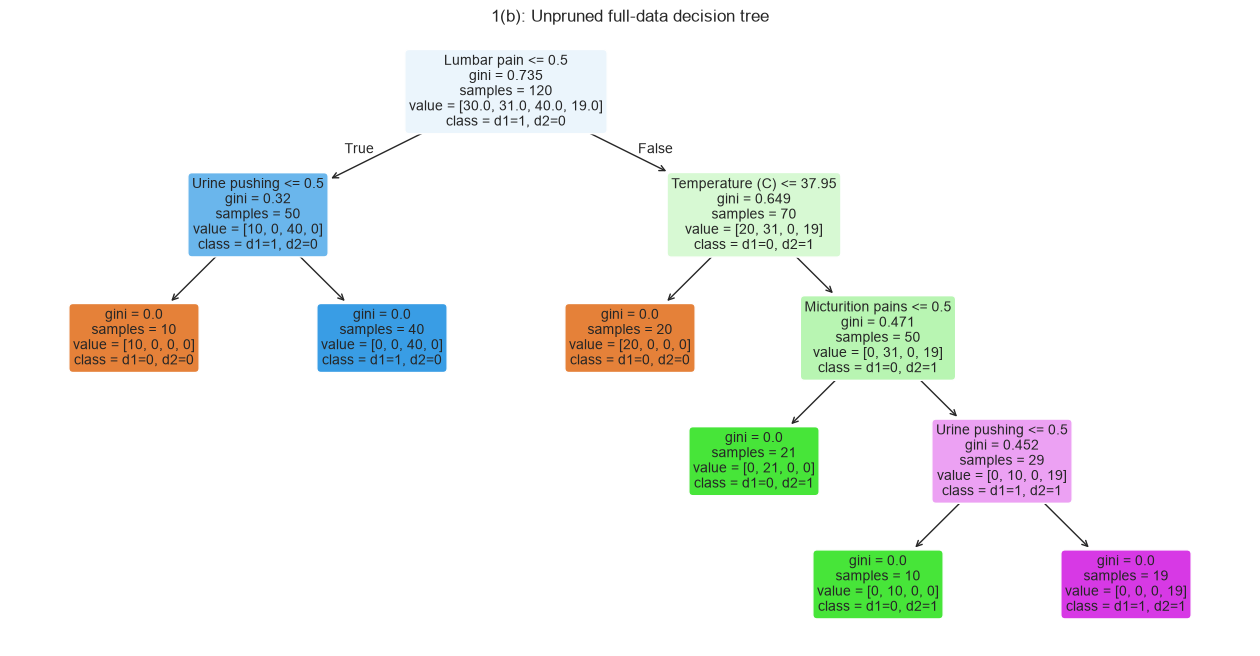

In [7]:
full=DecisionTreeClassifier(random_state=SEED,ccp_alpha=0).fit(Xd,yd)
def draw_tree(model,name,title):
    fig,ax=plt.subplots(figsize=(16,8))
    plot_tree(model,feature_names=feature_names,class_names=class_names,filled=True,
              rounded=True,proportion=False,precision=3,fontsize=10,ax=ax)
    ax.set_title(title)
    figure(fig,name,title+' All nodes and both diagnosis labels are shown.')
draw_tree(full,'tree_full','1(b): Unpruned full-data decision tree')

## 1(c) All root-to-leaf IF-THEN rules
Each conjunction is one complete path. Binary branches are translated back to yes/no, and leaf classes back to the original two diagnoses. Temperature thresholds retain the model threshold to sufficient precision. n is the training support of the leaf. The executable path conditions are checked against tree predictions for every record, with exactly one matching rule per record.

In [8]:
record_text('## 1(c) All root-to-leaf IF-THEN rules\nEach conjunction is one complete path. Binary branches are translated back to yes/no, and leaf classes back to the original two diagnoses. Temperature thresholds retain the model threshold to sufficient precision. n is the training support of the leaf. The executable path conditions are checked against tree predictions for every record, with exactly one matching rule per record.')

In [9]:
def extract_rules(model):
    t=model.tree_; rules=[]
    def walk(node,terms,conditions):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            j=int(t.feature[node]); threshold=float(t.threshold[node]); name=feature_names[j]
            for left,child in [(True,t.children_left[node]),(False,t.children_right[node])]:
                if j==0:
                    term=f'{name} {"<=" if left else ">"} {threshold:.8g}'
                else:
                    assert threshold==0.5
                    term=f'{name} = {"no" if left else "yes"}'
                walk(child,terms+[term],conditions+[(j,threshold,left)])
        else:
            cls=int(model.classes_[np.argmax(t.value[node][0])])
            text=('IF '+' AND '.join(terms) if terms else 'IF TRUE')+f' THEN bladder inflammation = {"yes" if cls//2 else "no"}; renal pelvis nephritis = {"yes" if cls%2 else "no"} (n={t.n_node_samples[node]}).'
            rules.append({'text':text,'conditions':conditions,'class':cls,'leaf':int(node)})
    walk(0,[],[])
    counts=np.zeros(len(Xd),int); prediction=np.full(len(Xd),-1)
    for r in rules:
        mask=np.ones(len(Xd),bool)
        for j,threshold,left in r['conditions']:
            mask &= (Xd.iloc[:,j].to_numpy()<=threshold) if left else (Xd.iloc[:,j].to_numpy()>threshold)
        assert mask.sum()==t.n_node_samples[r['leaf']]
        counts+=mask; prediction[mask]=r['class']
    assert np.all(counts==1) and np.array_equal(prediction,model.predict(Xd))
    return rules
full_rules=extract_rules(full)
for i,r in enumerate(full_rules,1): say(f'**Rule {i}.** '+r['text'])
(ROOT/'results'/'rules_full.json').write_text(json.dumps(full_rules,indent=2))

**Rule 1.** IF Lumbar pain = no AND Urine pushing = no THEN bladder inflammation = no; renal pelvis nephritis = no (n=10).

**Rule 2.** IF Lumbar pain = no AND Urine pushing = yes THEN bladder inflammation = yes; renal pelvis nephritis = no (n=40).

**Rule 3.** IF Lumbar pain = yes AND Temperature (C) <= 37.950001 THEN bladder inflammation = no; renal pelvis nephritis = no (n=20).

**Rule 4.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 AND Micturition pains = no THEN bladder inflammation = no; renal pelvis nephritis = yes (n=21).

**Rule 5.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 AND Micturition pains = yes AND Urine pushing = no THEN bladder inflammation = no; renal pelvis nephritis = yes (n=10).

**Rule 6.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 AND Micturition pains = yes AND Urine pushing = yes THEN bladder inflammation = yes; renal pelvis nephritis = yes (n=19).

2311

## 1(d) Cost-complexity pruning and interpretable minimum
CART minimizes training leaf impurity plus alpha times the number of leaves. To define a useful minimum, a predeclared grid of 401 alpha values from 0 through 0.4 is evaluated by shuffled stratified five-fold CV on exact-match powerset accuracy. This grid is independent of label-derived pruning breakpoints. Select the largest alpha whose mean accuracy is within one standard error of the best mean; ties therefore favor fewer leaves. The standard error is the sample standard deviation of five fold accuracies divided by sqrt(5). This is a practical simplicity rule, not a proof of globally minimal trees or statistical equivalence. Final candidates are then refitted on all 120 records. The full-data pruning path is reported descriptively, not used to construct the CV grid. A stump is explicitly compared to the chosen model.

In [10]:
record_text('## 1(d) Cost-complexity pruning and interpretable minimum\nCART minimizes training leaf impurity plus alpha times the number of leaves. To define a useful minimum, a predeclared grid of 401 alpha values from 0 through 0.4 is evaluated by shuffled stratified five-fold CV on exact-match powerset accuracy. This grid is independent of label-derived pruning breakpoints. Select the largest alpha whose mean accuracy is within one standard error of the best mean; ties therefore favor fewer leaves. The standard error is the sample standard deviation of five fold accuracies divided by sqrt(5). This is a practical simplicity rule, not a proof of globally minimal trees or statistical equivalence. Final candidates are then refitted on all 120 records. The full-data pruning path is reported descriptively, not used to construct the CV grid. A stump is explicitly compared to the chosen model.')

,alpha breakpoint,Leaf impurity,Nodes,Leaves,Depth,Train exact accuracy
0,0.00000000,0.00000000,11,6,4,1.00000000
1,0.09816667,0.19633333,7,4,2,0.84166667
2,0.13333333,0.32966667,5,3,2,0.75833333
3,0.18200000,0.51166667,3,2,1,0.59166667
4,0.22291667,0.73458333,1,1,0,0.33333333


,Tree,alpha,Nodes,Leaves,Depth,Train accuracy,Train Hamming loss,CV accuracy
0,Unpruned,0.000,11,6,4,1.00000000,0.0000,0.99166667
1,Selected,0.089,11,6,4,1.00000000,0.0000,0.99166667
2,Stump baseline,1.000,1,1,0,0.33333333,0.4625,0.33333333


The best CV accuracy is **0.9917**, SE **0.0083**; the acceptance threshold is **0.9833**. Selected alpha = **0.089**. The selected tree has **6 leaves** and depth **4** versus **6 leaves** and depth **4** before pruning. No smaller subtree meets this criterion; keeping the original structure is preferable to sacrificing useful accuracy.

These CV scores informed alpha selection and are not an independent post-selection performance estimate. There is no separate test set in Question 1, in accordance with the full-data fitting requirement.

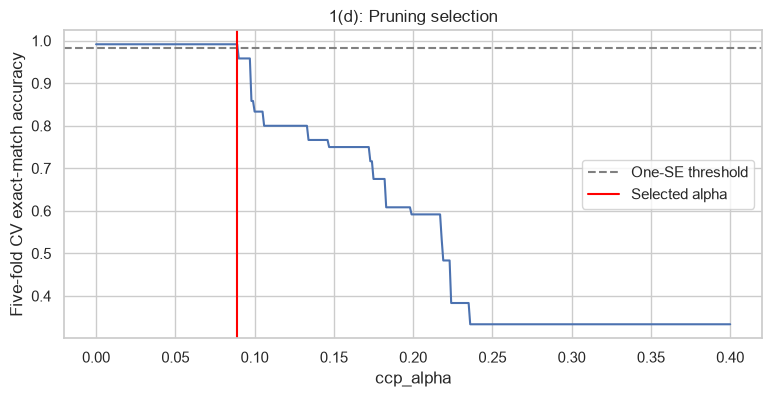

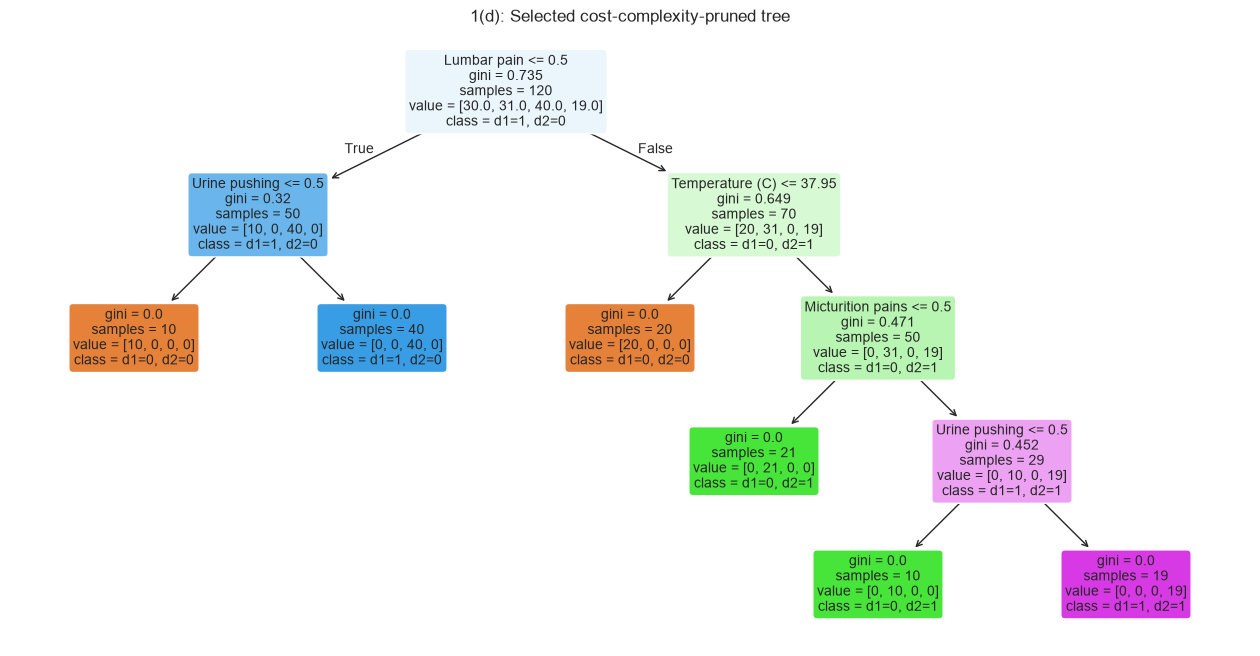

**Pruned rule 1.** IF Lumbar pain = no AND Urine pushing = no THEN bladder inflammation = no; renal pelvis nephritis = no (n=10).

**Pruned rule 2.** IF Lumbar pain = no AND Urine pushing = yes THEN bladder inflammation = yes; renal pelvis nephritis = no (n=40).

**Pruned rule 3.** IF Lumbar pain = yes AND Temperature (C) <= 37.950001 THEN bladder inflammation = no; renal pelvis nephritis = no (n=20).

**Pruned rule 4.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 AND Micturition pains = no THEN bladder inflammation = no; renal pelvis nephritis = yes (n=21).

**Pruned rule 5.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 AND Micturition pains = yes AND Urine pushing = no THEN bladder inflammation = no; renal pelvis nephritis = yes (n=10).

**Pruned rule 6.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 AND Micturition pains = yes AND Urine pushing = yes THEN bladder inflammation = yes; renal pelvis nephritis = yes (n=19).

**Additional 1(d): an actually smaller pruning-path candidate.** The original CV results and one-SE selection above are retained. For an interpretable alternative, fit the trees at the full-data cost-complexity breakpoints and choose the first non-stump subtree whose leaf count is strictly below the unpruned tree. This rule does not prescribe a leaf count or use the regression test data. The alternative is a descriptive complexity/accuracy comparison, not a replacement for the CV-selected model.

,Tree,ccp_alpha,Leaves,Depth,Train exact accuracy,Train errors
0,Unpruned,0.00000000,6,4,1.00000000,0
1,One-SE selected,0.08900000,6,4,1.00000000,0
2,Reduced path candidate,0.09816667,4,2,0.84166667,19


The first actual reduction occurs at **ccp_alpha = 0.0981666666667**. It changes the tree from **6 leaves, depth 4, training exact-match accuracy 100.00%** to **4 leaves, depth 2, accuracy 84.17%**: a loss of **15.83 percentage points** and **19 / 120** misclassified diagnosis pairs. All figures and metrics here are computed from fitted trees, rather than a hard-coded leaf target.

The reduced tree omits these splitting features: **Micturition pains**. It gives **4** diagnostic paths and at most **2** decisions per path, compared with **6** paths and at most **4** decisions before pruning. This is easier to trace, but merged leaves assign a majority diagnosis pair to patients whose original diagnoses differ. The errors comprise **19 bladder-inflammation labels** and **0 renal-pelvis-nephritis labels**. Training accuracy describes these illustrative records; it is not a generalization estimate.

**Selection conclusion is unchanged:** the original one-SE procedure retains **ccp_alpha = 0.089**, with **6 leaves**. The smaller candidate is shown to make the interpretability cost concrete, but its loss of diagnostic accuracy is not hidden or accepted as a new CV optimum. There is no claim that this full-data path choice has an independent validation estimate. A stump would be still shorter, but would discard substantially more diagnostic information.

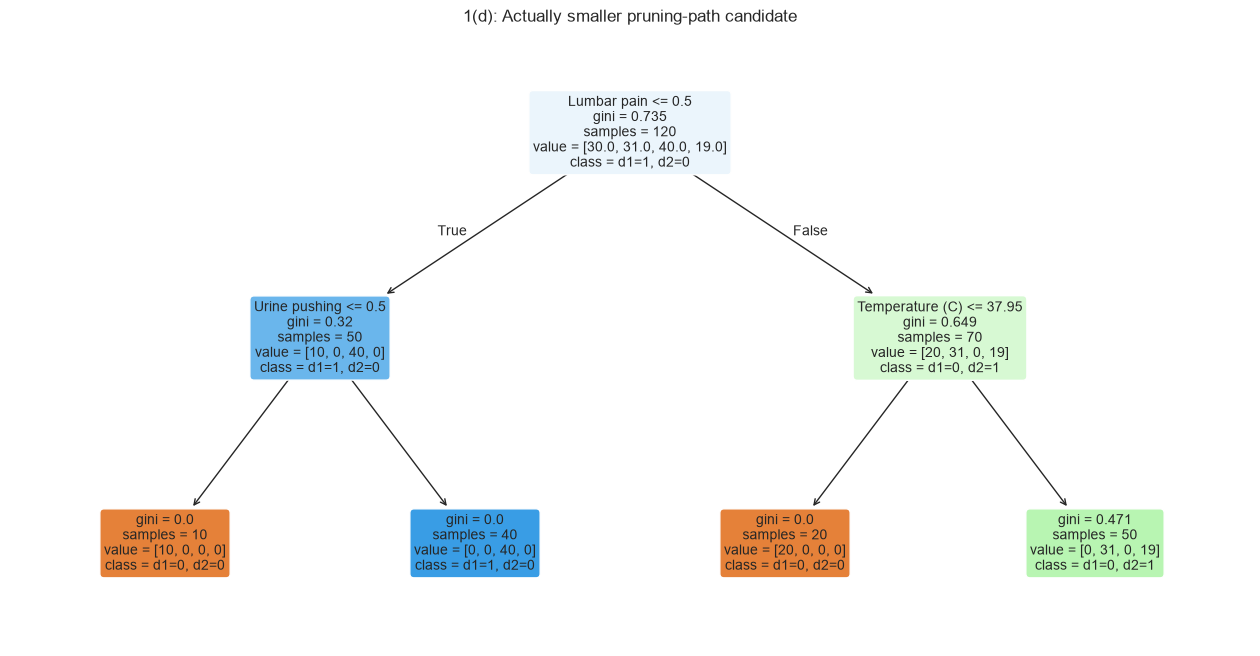

**Reduced-candidate rule 1.** IF Lumbar pain = no AND Urine pushing = no THEN bladder inflammation = no; renal pelvis nephritis = no (n=10).

**Reduced-candidate rule 2.** IF Lumbar pain = no AND Urine pushing = yes THEN bladder inflammation = yes; renal pelvis nephritis = no (n=40).

**Reduced-candidate rule 3.** IF Lumbar pain = yes AND Temperature (C) <= 37.950001 THEN bladder inflammation = no; renal pelvis nephritis = no (n=20).

**Reduced-candidate rule 4.** IF Lumbar pain = yes AND Temperature (C) > 37.950001 THEN bladder inflammation = no; renal pelvis nephritis = yes (n=50).

607

In [11]:
dcv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
alpha_grid=np.linspace(0,0.4,401)
prune_rows=[]
for a in alpha_grid:
    scores=cross_val_score(DecisionTreeClassifier(random_state=SEED,ccp_alpha=float(a)),Xd,yd,cv=dcv,scoring='accuracy')
    prune_rows.append({'alpha':a,'CV accuracy':scores.mean(),'SE':scores.std(ddof=1)/np.sqrt(5)})
pruning=pd.DataFrame(prune_rows)
best_idx=int(pruning['CV accuracy'].idxmax())
threshold=pruning.loc[best_idx,'CV accuracy']-pruning.loc[best_idx,'SE']
chosen_alpha=float(pruning.loc[pruning['CV accuracy']>=threshold-1e-12,'alpha'].max())
pruned=DecisionTreeClassifier(random_state=SEED,ccp_alpha=chosen_alpha).fit(Xd,yd)
stump=DecisionTreeClassifier(random_state=SEED,ccp_alpha=1).fit(Xd,yd)
pruning.to_csv(ROOT/'results'/'pruning_grid.csv',index=False)
path=full.cost_complexity_pruning_path(Xd,yd)
path_rows=[]
for a,imp in zip(path.ccp_alphas,path.impurities):
    t=DecisionTreeClassifier(random_state=SEED,ccp_alpha=float(a)).fit(Xd,yd)
    path_rows.append({'alpha breakpoint':a,'Leaf impurity':imp,'Nodes':t.tree_.node_count,'Leaves':t.get_n_leaves(),'Depth':t.get_depth(),'Train exact accuracy':t.score(Xd,yd)})
table(pd.DataFrame(path_rows),'pruning_path')
comparison=[]
for name,t in [('Unpruned',full),('Selected',pruned),('Stump baseline',stump)]:
    scores=cross_val_score(t,Xd,yd,cv=dcv,scoring='accuracy')
    pred=t.predict(Xd).astype(int); recovered=np.column_stack((pred//2,pred%2))
    comparison.append({'Tree':name,'alpha':t.ccp_alpha,'Nodes':t.tree_.node_count,'Leaves':t.get_n_leaves(),'Depth':t.get_depth(),'Train accuracy':accuracy_score(yd,pred),'Train Hamming loss':hamming_loss(Yd,recovered),'CV accuracy':scores.mean()})
table(pd.DataFrame(comparison),'tree_comparison')
say(f'The best CV accuracy is **{pruning.loc[best_idx,"CV accuracy"]:.4f}**, SE **{pruning.loc[best_idx,"SE"]:.4f}**; the acceptance threshold is **{threshold:.4f}**. Selected alpha = **{chosen_alpha:.3f}**. The selected tree has **{pruned.get_n_leaves()} leaves** and depth **{pruned.get_depth()}** versus **{full.get_n_leaves()} leaves** and depth **{full.get_depth()}** before pruning. '+('No smaller subtree meets this criterion; keeping the original structure is preferable to sacrificing useful accuracy.' if full.get_n_leaves()==pruned.get_n_leaves() else 'This reduces the number of diagnostic paths while meeting the predeclared CV accuracy criterion.'))
assert pruned.get_n_leaves()>1, 'A meaningless stump must not be accepted.'
say('These CV scores informed alpha selection and are not an independent post-selection performance estimate. There is no separate test set in Question 1, in accordance with the full-data fitting requirement.')
fig,ax=plt.subplots(figsize=(9,4)); ax.plot(pruning['alpha'],pruning['CV accuracy']); ax.axhline(threshold,ls='--',color='gray',label='One-SE threshold'); ax.axvline(chosen_alpha,color='red',label='Selected alpha'); ax.set(xlabel='ccp_alpha',ylabel='Five-fold CV exact-match accuracy',title='1(d): Pruning selection'); ax.legend(); figure(fig,'pruning_selection','Alpha selection using only the acute-inflammations data.')
draw_tree(pruned,'tree_pruned','1(d): Selected cost-complexity-pruned tree')
pruned_rules=extract_rules(pruned)
for i,r in enumerate(pruned_rules,1): say(f'**Pruned rule {i}.** '+r['text'])
(ROOT/'results'/'rules_pruned.json').write_text(json.dumps(pruned_rules,indent=2))

# Additional 1(d) analysis: inspect a genuinely smaller path subtree without
# replacing the original cross-validation / one-standard-error selection.
say('**Additional 1(d): an actually smaller pruning-path candidate.** The original CV results and one-SE selection above are retained. For an interpretable alternative, fit the trees at the full-data cost-complexity breakpoints and choose the first non-stump subtree whose leaf count is strictly below the unpruned tree. This rule does not prescribe a leaf count or use the regression test data. The alternative is a descriptive complexity/accuracy comparison, not a replacement for the CV-selected model.')
smaller_path_candidates=[]
for alpha in path.ccp_alphas:
    path_tree=DecisionTreeClassifier(random_state=SEED,ccp_alpha=float(alpha)).fit(Xd,yd)
    if 1 < path_tree.get_n_leaves() < full.get_n_leaves():
        smaller_path_candidates.append((float(alpha),path_tree))
assert smaller_path_candidates, 'The path contains no non-stump, smaller subtree.'
candidate_alpha,reduced_candidate=min(smaller_path_candidates,key=lambda item:item[0])
assert reduced_candidate.get_n_leaves() < full.get_n_leaves()
reduced_rows=[]
for label,model in [('Unpruned',full),('One-SE selected',pruned),('Reduced path candidate',reduced_candidate)]:
    predictions=model.predict(Xd).astype(int)
    reduced_rows.append({'Tree':label,'ccp_alpha':float(model.ccp_alpha),'Leaves':model.get_n_leaves(),
                         'Depth':model.get_depth(),'Train exact accuracy':accuracy_score(yd,predictions),
                         'Train errors':int(np.count_nonzero(predictions!=yd))})
table(pd.DataFrame(reduced_rows),'tree_reduced_candidate_comparison')
full_accuracy=full.score(Xd,yd)
reduced_accuracy=reduced_candidate.score(Xd,yd)
reduced_predictions=reduced_candidate.predict(Xd).astype(int)
reduced_errors=int(np.count_nonzero(reduced_predictions!=yd))
bladder_errors=int(np.count_nonzero(reduced_predictions//2!=Yd[:,0]))
renal_errors=int(np.count_nonzero(reduced_predictions%2!=Yd[:,1]))
accuracy_loss_pp=(full_accuracy-reduced_accuracy)*100
used_features=lambda model: {feature_names[j] for j in model.tree_.feature if j>=0}
removed_features=sorted(used_features(full)-used_features(reduced_candidate))
say(f'The first actual reduction occurs at **ccp_alpha = {candidate_alpha:.12g}**. It changes the tree from **{full.get_n_leaves()} leaves, depth {full.get_depth()}, training exact-match accuracy {full_accuracy:.2%}** to **{reduced_candidate.get_n_leaves()} leaves, depth {reduced_candidate.get_depth()}, accuracy {reduced_accuracy:.2%}**: a loss of **{accuracy_loss_pp:.2f} percentage points** and **{reduced_errors} / {len(Xd)}** misclassified diagnosis pairs. All figures and metrics here are computed from fitted trees, rather than a hard-coded leaf target.')
say(f'The reduced tree omits these splitting features: **{", ".join(removed_features) if removed_features else "none"}**. It gives **{reduced_candidate.get_n_leaves()}** diagnostic paths and at most **{reduced_candidate.get_depth()}** decisions per path, compared with **{full.get_n_leaves()}** paths and at most **{full.get_depth()}** decisions before pruning. This is easier to trace, but merged leaves assign a majority diagnosis pair to patients whose original diagnoses differ. The errors comprise **{bladder_errors} bladder-inflammation labels** and **{renal_errors} renal-pelvis-nephritis labels**. Training accuracy describes these illustrative records; it is not a generalization estimate.')
say(f'**Selection conclusion is unchanged:** the original one-SE procedure retains **ccp_alpha = {chosen_alpha:.3f}**, with **{pruned.get_n_leaves()} leaves**. The smaller candidate is shown to make the interpretability cost concrete, but its loss of diagnostic accuracy is not hidden or accepted as a new CV optimum. There is no claim that this full-data path choice has an independent validation estimate. A stump would be still shorter, but would discard substantially more diagnostic information.')
draw_tree(reduced_candidate,'tree_reduced_candidate','1(d): Actually smaller pruning-path candidate')
reduced_candidate_rules=extract_rules(reduced_candidate)
assert len(reduced_candidate_rules)==reduced_candidate.get_n_leaves()
for i,rule in enumerate(reduced_candidate_rules,1):
    say(f'**Reduced-candidate rule {i}.** '+rule['text'])
(ROOT/'results'/'rules_reduced_candidate.json').write_text(json.dumps(reduced_candidate_rules,indent=2))
reduced_details={'selection_rule':'First full-data cost-complexity breakpoint giving a strictly smaller, non-stump subtree',
                 'candidate_alpha':candidate_alpha,'candidate_leaves':int(reduced_candidate.get_n_leaves()),
                 'candidate_depth':int(reduced_candidate.get_depth()),'candidate_training_accuracy':reduced_accuracy,
                 'training_errors':reduced_errors,'bladder_label_errors':bladder_errors,'renal_label_errors':renal_errors,
                 'accuracy_loss_percentage_points':accuracy_loss_pp,'original_one_se_alpha':chosen_alpha,
                 'original_one_se_leaves':int(pruned.get_n_leaves()),'original_one_se_conclusion_retained':True,
                 'all_leaf_rules_checked_against_tree_predictions':True,'regression_models_retrained':False}
(ROOT/'results'/'reduced_candidate_details.json').write_text(json.dumps(reduced_details,indent=2))

## 2(a) Communities and Crime: data and ordered split
Read the 128 attribute names directly from @attribute lines in communities.names. Keep original file order: training is original rows 1-1495, test is rows 1496-1994. The target is ViolentCrimesPerPop. The provided data were already normalized approximately to [0,1]; this is different from standardization to zero mean and unit variance. The data combine the 1990 Census, 1990 LEMAS and 1995 FBI UCR; normalization parameters used by the original dataset creator cannot be undone. All additional preprocessing here is learned solely from training data.

In [12]:
record_text('## 2(a) Communities and Crime: data and ordered split\nRead the 128 attribute names directly from @attribute lines in communities.names. Keep original file order: training is original rows 1-1495, test is rows 1496-1994. The target is ViolentCrimesPerPop. The provided data were already normalized approximately to [0,1]; this is different from standardization to zero mean and unit variance. The data combine the 1990 Census, 1990 LEMAS and 1995 FBI UCR; normalization parameters used by the original dataset creator cannot be undone. All additional preprocessing here is learned solely from training data.')

In [13]:
names_text=(DATA/'communities.names').read_text()
columns=re.findall(r'^@attribute\s+(\S+)\s+',names_text,re.MULTILINE|re.IGNORECASE)
assert len(columns)==128 and len(set(columns))==128
communities=pd.read_csv(DATA/'communities.data',names=columns,header=None,na_values='?')
assert communities.shape==(1994,128)
nonpredictive=['state','county','community','communityname','fold']
target='ViolentCrimesPerPop'
X=communities.drop(columns=nonpredictive+[target]).astype(float)
y=communities[target].astype(float)
Xtrain=X.iloc[:1495].copy(); Xtest=X.iloc[1495:].copy()
ytrain=y.iloc[:1495].copy(); ytest=y.iloc[1495:].copy()
assert Xtrain.shape==(1495,122) and Xtest.shape==(499,122)
assert not y.isna().any() and Xtrain.index[-1]==1494 and Xtest.index[0]==1495
cv=list(KFold(n_splits=5,shuffle=True,random_state=SEED).split(Xtrain))
np.savez(ROOT/'results'/'cv_splits.npz',**{f'{kind}_{i}':indices for i,pair in enumerate(cv) for kind,indices in zip(['train','valid'],pair)})
say(f'Validated raw shape: **{communities.shape}**. Training: **{Xtrain.shape}**. Test: **{Xtest.shape}**. Target excluded from predictors; all five nonpredictive fields removed.')

Validated raw shape: **(1994, 128)**. Training: **(1495, 122)**. Test: **(499, 122)**. Target excluded from predictors; all five nonpredictive fields removed.

## 2(b) Missing values and imputation
Question marks are parsed as NaN. Median imputation is robust to skew and retains all 122 predictors, including sparsely observed LEMAS variables. A median cannot reconstruct missing information or remove selection bias: LEMAS coverage is highly nonrandom according to the supplied documentation. No rows or predictive columns are dropped. An all-missing column within a training fold is retained and filled with zero via keep_empty_features=True (the audit below checks whether this fallback is actually needed). The descriptive training matrix is median-imputed using training rows only. Predictive CV uses a separate SimpleImputer inside every Pipeline; the descriptive matrix is never passed to GridSearchCV.

In [14]:
record_text('## 2(b) Missing values and imputation\nQuestion marks are parsed as NaN. Median imputation is robust to skew and retains all 122 predictors, including sparsely observed LEMAS variables. A median cannot reconstruct missing information or remove selection bias: LEMAS coverage is highly nonrandom according to the supplied documentation. No rows or predictive columns are dropped. An all-missing column within a training fold is retained and filled with zero via keep_empty_features=True (the audit below checks whether this fallback is actually needed). The descriptive training matrix is median-imputed using training rows only. Predictive CV uses a separate SimpleImputer inside every Pipeline; the descriptive matrix is never passed to GridSearchCV.')

In [15]:
missing=pd.DataFrame({'Feature':Xtrain.columns,'Train missing':Xtrain.isna().sum().values,'Train missing fraction':Xtrain.isna().mean().values})
table(missing.loc[missing['Train missing']>0].reset_index(drop=True),'missingness')
empty_folds=sum(int(Xtrain.iloc[tr].isna().all().sum()) for tr,va in cv)
say(f'All-missing training-fold columns across five folds: **{empty_folds}**. Number of predictive columns dropped: **0**.')
descriptive_imputer=SimpleImputer(strategy='median',keep_empty_features=True)
Xdesc=pd.DataFrame(descriptive_imputer.fit_transform(Xtrain),columns=Xtrain.columns,index=Xtrain.index)
assert Xdesc.shape==Xtrain.shape and np.isfinite(Xdesc).all().all()
def make_pipe(model,scale=False,pca=False):
    steps=[('impute',SimpleImputer(strategy='median',keep_empty_features=True))]
    if scale: steps.append(('scale',StandardScaler()))
    if pca: steps.append(('pca',PCA(svd_solver='full')))
    steps.append(('model',model))
    return Pipeline(steps)

,Feature,Train missing,Train missing fraction
0,OtherPerCap,1,0.00066890
1,LemasSwornFT,1256,0.84013378
2,LemasSwFTPerPop,1256,0.84013378
3,LemasSwFTFieldOps,1256,0.84013378
4,LemasSwFTFieldPerPop,1256,0.84013378
5,LemasTotalReq,1256,0.84013378
6,LemasTotReqPerPop,1256,0.84013378
7,PolicReqPerOffic,1256,0.84013378
8,PolicPerPop,1256,0.84013378
9,RacialMatchCommPol,1256,0.84013378


All-missing training-fold columns across five folds: **0**. Number of predictive columns dropped: **0**.

## 2(c) Feature correlation matrix
Pearson correlations below use the median-imputed 1495-row training matrix, before standardization. The target is excluded. All 122 feature labels are shown in a large overview and four enlarged row panels; the complete numeric matrix is also exported. Strong blocks of correlation indicate redundant predictors and motivate regularization and PCR. Imputation can alter correlations, especially for sparse LEMAS fields. These correlations describe association, not causation.

In [16]:
record_text('## 2(c) Feature correlation matrix\nPearson correlations below use the median-imputed 1495-row training matrix, before standardization. The target is excluded. All 122 feature labels are shown in a large overview and four enlarged row panels; the complete numeric matrix is also exported. Strong blocks of correlation indicate redundant predictors and motivate regularization and PCR. Imputation can alter correlations, especially for sparse LEMAS fields. These correlations describe association, not causation.')

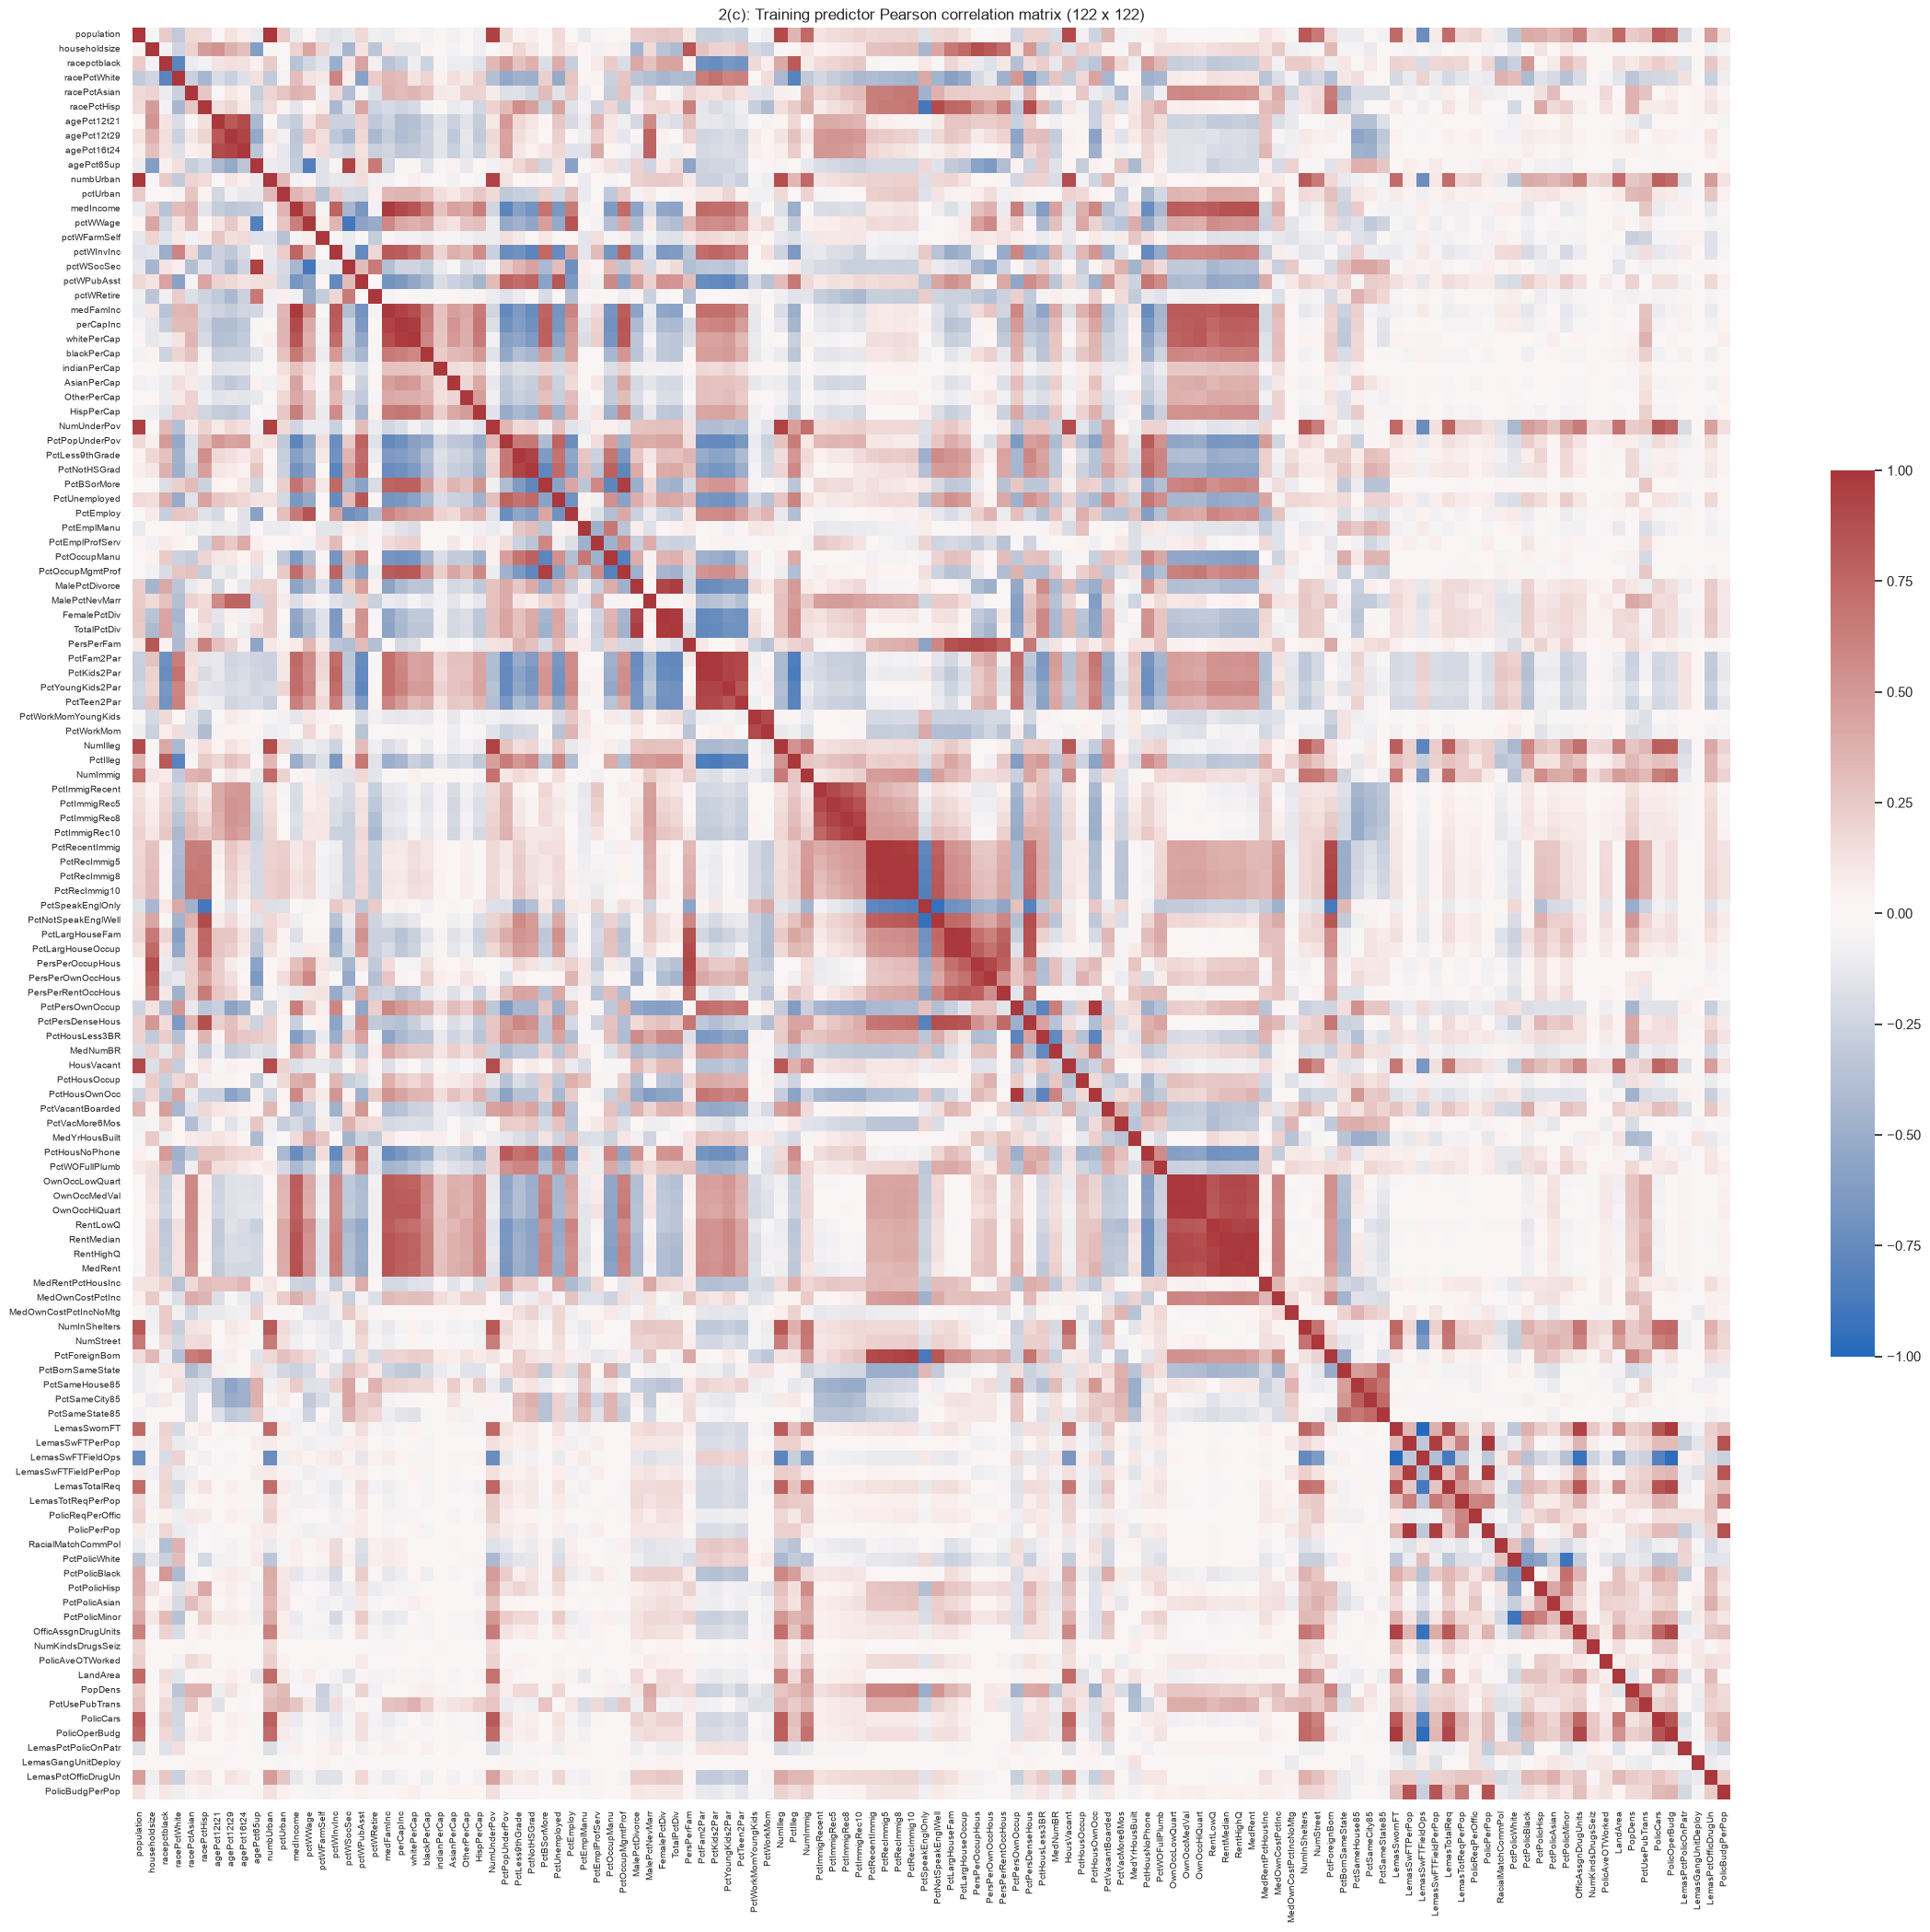

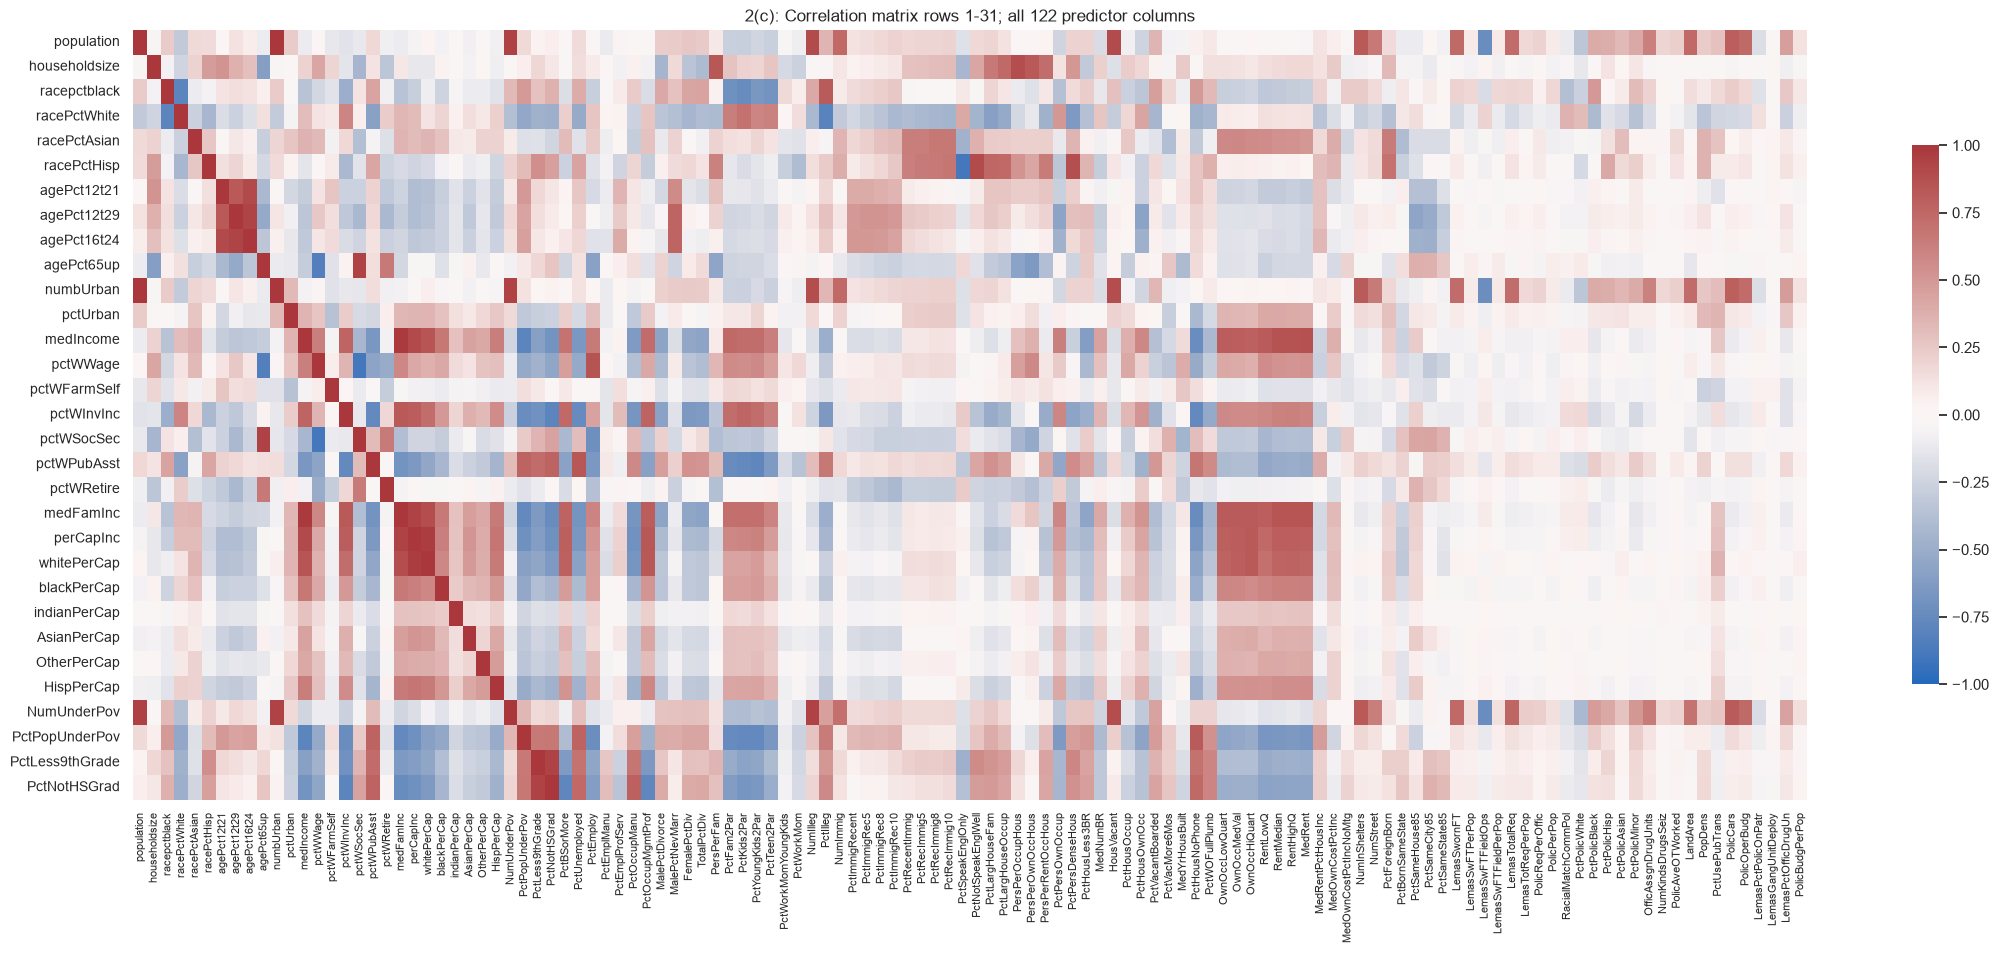

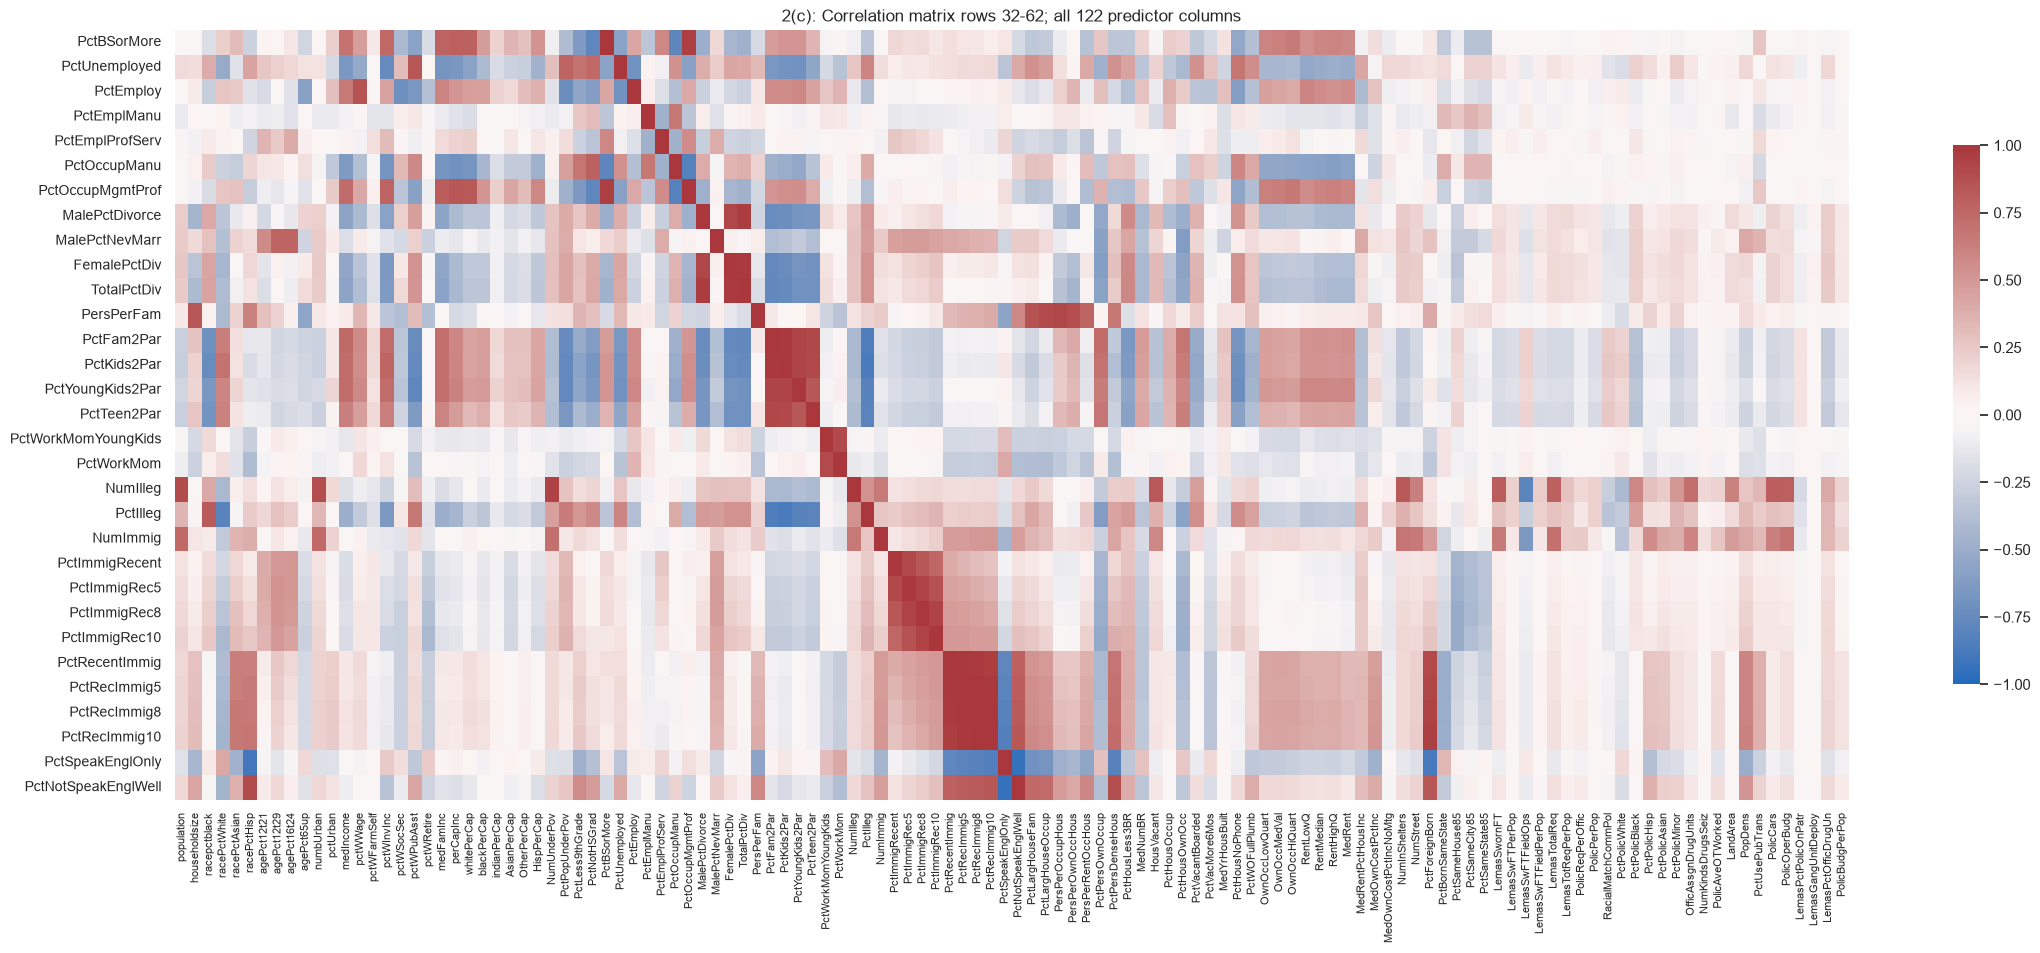

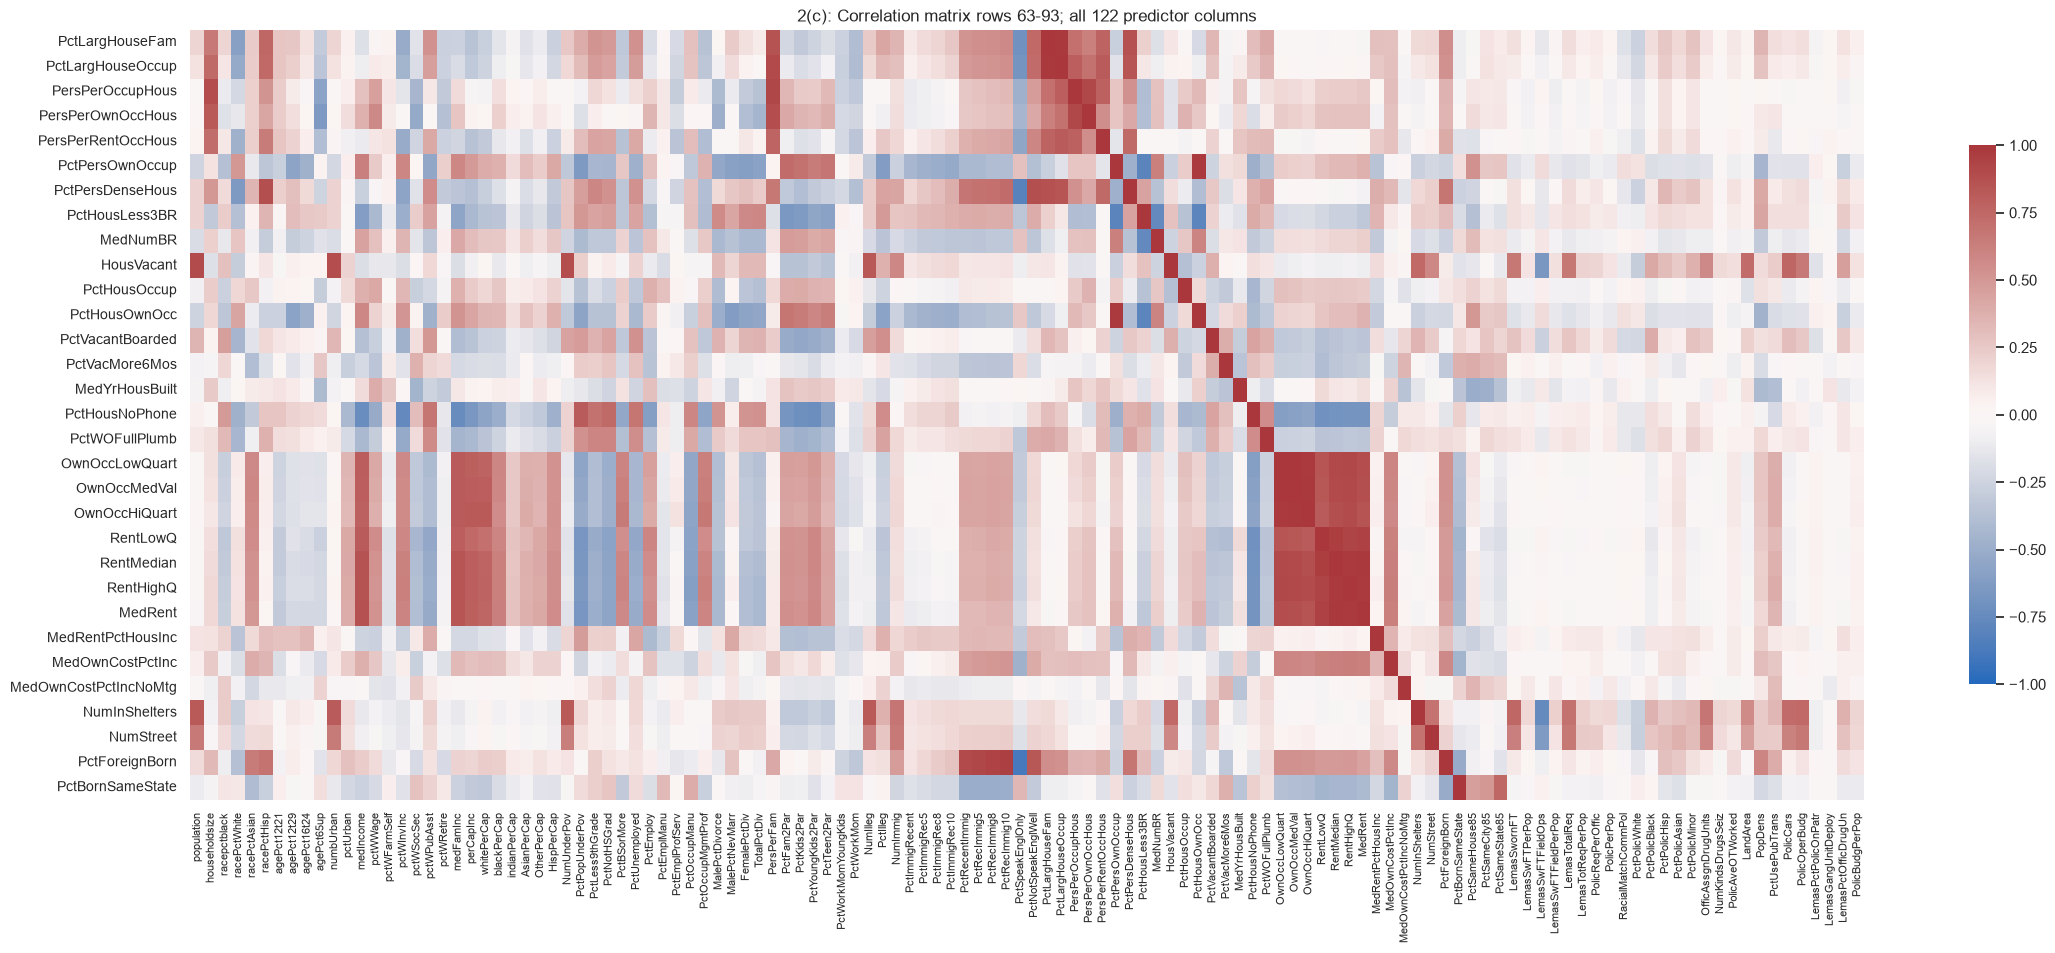

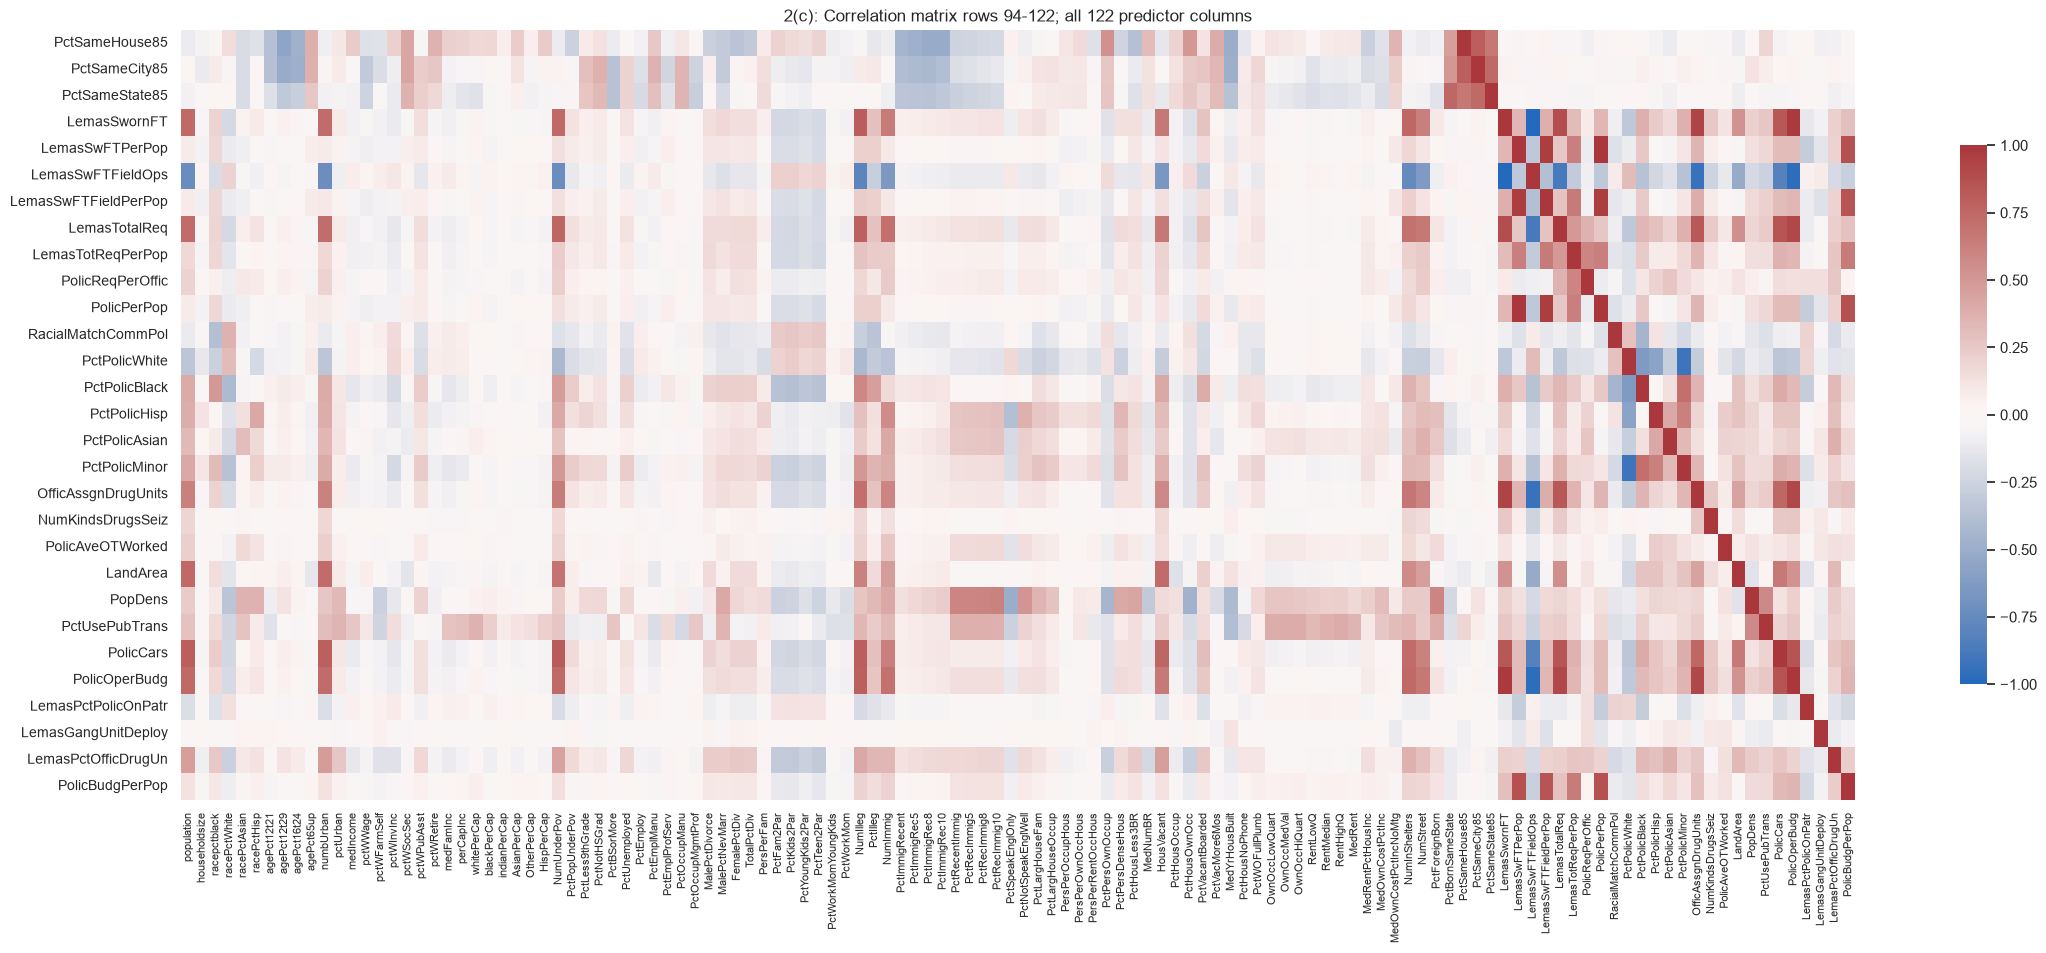

In [17]:
corr=Xdesc.corr(); corr.to_csv(ROOT/'results'/'feature_correlations.csv')
fig,ax=plt.subplots(figsize=(28,25))
sns.heatmap(corr,vmin=-1,vmax=1,cmap='vlag',xticklabels=True,yticklabels=True,ax=ax,cbar_kws={'shrink':0.5})
ax.tick_params(axis='both',labelsize=7); ax.set_title('2(c): Training predictor Pearson correlation matrix (122 x 122)')
figure(fig,'correlation_overview','Full training feature correlation matrix; use the following enlarged panels for labels.')
for start in range(0,122,31):
    end=min(start+31,122)
    fig,ax=plt.subplots(figsize=(27,10))
    sns.heatmap(corr.iloc[start:end],vmin=-1,vmax=1,cmap='vlag',xticklabels=True,yticklabels=True,ax=ax,cbar_kws={'shrink':0.7})
    ax.tick_params(axis='x',labelsize=8); ax.tick_params(axis='y',labelsize=10)
    ax.set_title(f'2(c): Correlation matrix rows {start+1}-{end}; all 122 predictor columns')
    figure(fig,f'correlation_panel_{start//31+1}',f'Enlarged matrix panel {start//31+1}: training predictors {start+1}-{end}.')

## 2(d) Coefficient of variation for every predictor
CV = s/m uses sample standard deviation with ddof=1 and sample mean over the median-imputed training rows only. CV is computed before standardization. A nonzero constant with nonzero mean has CV=0; any zero (or numerically near-zero, absolute tolerance 1e-12) mean has undefined CV and is excluded from ranking. All-zero columns are also undefined. This rule avoids replacing an undefined ratio with an arbitrary large number. The target and identifier fields are excluded. CV is sensitive to the dataset's normalization origin and does not measure predictive importance.

In [18]:
record_text("## 2(d) Coefficient of variation for every predictor\nCV = s/m uses sample standard deviation with ddof=1 and sample mean over the median-imputed training rows only. CV is computed before standardization. A nonzero constant with nonzero mean has CV=0; any zero (or numerically near-zero, absolute tolerance 1e-12) mean has undefined CV and is excluded from ranking. All-zero columns are also undefined. This rule avoids replacing an undefined ratio with an arbitrary large number. The target and identifier fields are excluded. CV is sensitive to the dataset's normalization origin and does not measure predictive importance.")

In [19]:
means=Xdesc.mean(); sds=Xdesc.std(ddof=1)
cv_values=sds/means.mask(np.isclose(means,0,atol=1e-12,rtol=0))
cv_table=pd.DataFrame({'Feature':Xdesc.columns,'Mean':means.values,'Sample SD (ddof=1)':sds.values,'CV':cv_values.values}).sort_values('CV',ascending=False,na_position='last').reset_index(drop=True)
table(cv_table,'coefficient_of_variation')
say(f'Undefined CVs: **{cv_values.isna().sum()}**; constant training predictors: **{(sds==0).sum()}**. All 122 coefficients are reported above and in results/coefficient_of_variation.csv.')

,Feature,Mean,Sample SD (ddof=1),CV
0,PctPolicAsian,0.01625418,0.08983781,5.52705874
1,NumStreet,0.02298328,0.09866544,4.29292299
2,NumInShelters,0.02959866,0.10273554,3.47095214
3,NumIlleg,0.03720401,0.11380575,3.05896435
4,NumImmig,0.03059532,0.08954134,2.92663525
5,LemasPctOfficDrugUn,0.09330435,0.23820092,2.55294551
6,NumUnderPov,0.05684950,0.13316672,2.34244312
7,LemasSwornFT,0.02874916,0.06462932,2.24804157
8,population,0.05816722,0.13035883,2.24110462
9,numbUrban,0.06464883,0.13178415,2.03846149


Undefined CVs: **0**; constant training predictors: **0**. All 122 coefficients are reported above and in results/coefficient_of_variation.csv.

## 2(e) The 11 highest-CV predictors: scatter plots and box plots
The count is floor(sqrt(128))=11 as specified, even though only 122 columns are predictive. These plots use the same imputed training rows. Each scatter plot has a predictor on the horizontal axis and ViolentCrimesPerPop on the vertical axis; each box plot summarizes one predictor. The 11-feature selection does not restrict subsequent regression models.

Scatter patterns can suggest skew, outliers, nonlinear associations, and heteroskedasticity. Neither scatter plots nor box plots establish statistical significance. Formal inference would require a specified null, a suitable model and assumptions, uncertainty estimates and multiple-comparison handling. Large CV alone does not imply a significant relationship with the target, and these observational data cannot establish causal effects.

In [20]:
record_text('## 2(e) The 11 highest-CV predictors: scatter plots and box plots\nThe count is floor(sqrt(128))=11 as specified, even though only 122 columns are predictive. These plots use the same imputed training rows. Each scatter plot has a predictor on the horizontal axis and ViolentCrimesPerPop on the vertical axis; each box plot summarizes one predictor. The 11-feature selection does not restrict subsequent regression models.\n\nScatter patterns can suggest skew, outliers, nonlinear associations, and heteroskedasticity. Neither scatter plots nor box plots establish statistical significance. Formal inference would require a specified null, a suitable model and assumptions, uncertainty estimates and multiple-comparison handling. Large CV alone does not imply a significant relationship with the target, and these observational data cannot establish causal effects.')

,Feature,Mean,Sample SD (ddof=1),CV
0,PctPolicAsian,0.01625418,0.08983781,5.52705874
1,NumStreet,0.02298328,0.09866544,4.29292299
2,NumInShelters,0.02959866,0.10273554,3.47095214
3,NumIlleg,0.03720401,0.11380575,3.05896435
4,NumImmig,0.03059532,0.08954134,2.92663525
5,LemasPctOfficDrugUn,0.09330435,0.23820092,2.55294551
6,NumUnderPov,0.05684950,0.13316672,2.34244312
7,LemasSwornFT,0.02874916,0.06462932,2.24804157
8,population,0.05816722,0.13035883,2.24110462
9,numbUrban,0.06464883,0.13178415,2.03846149


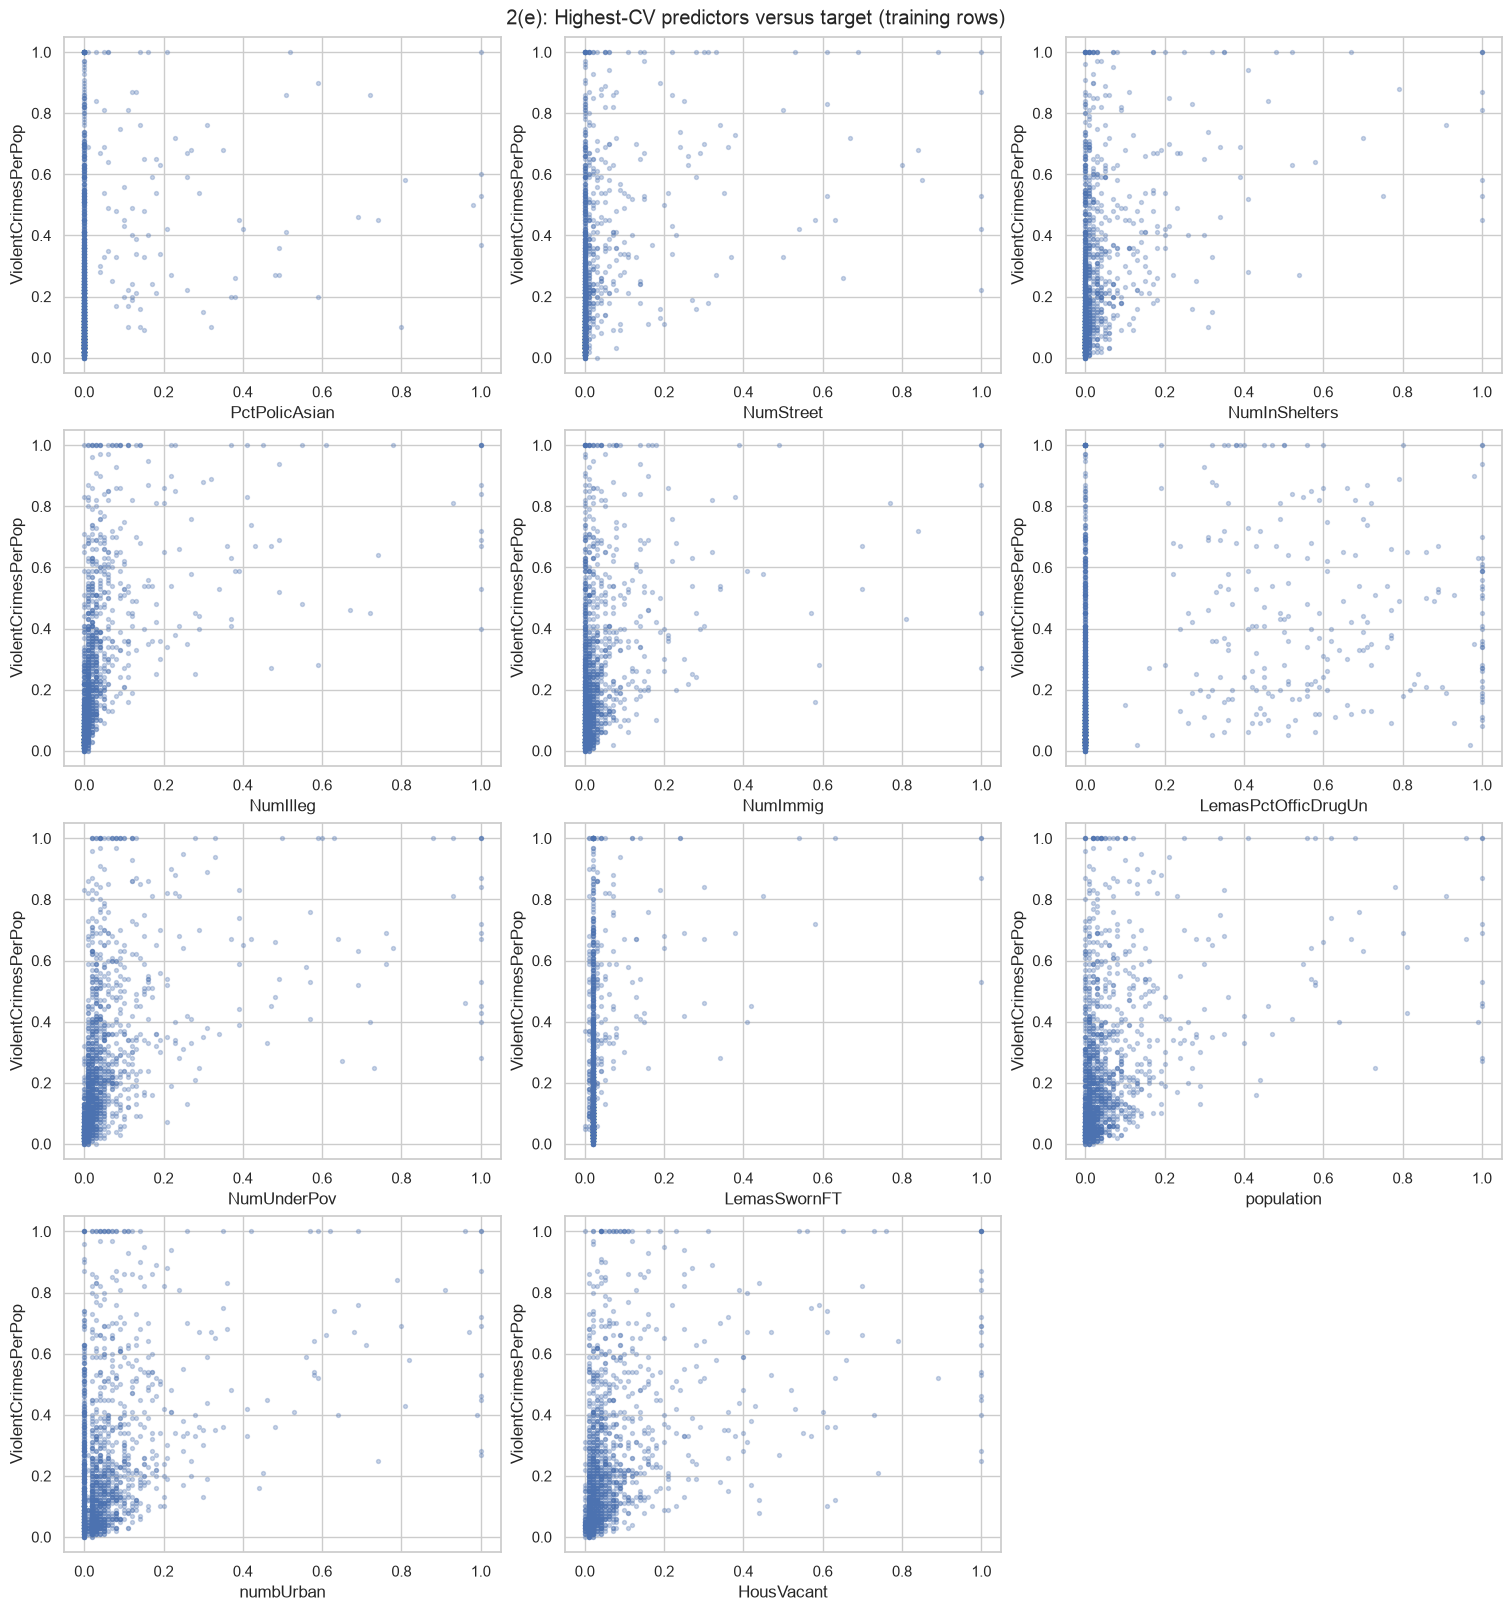

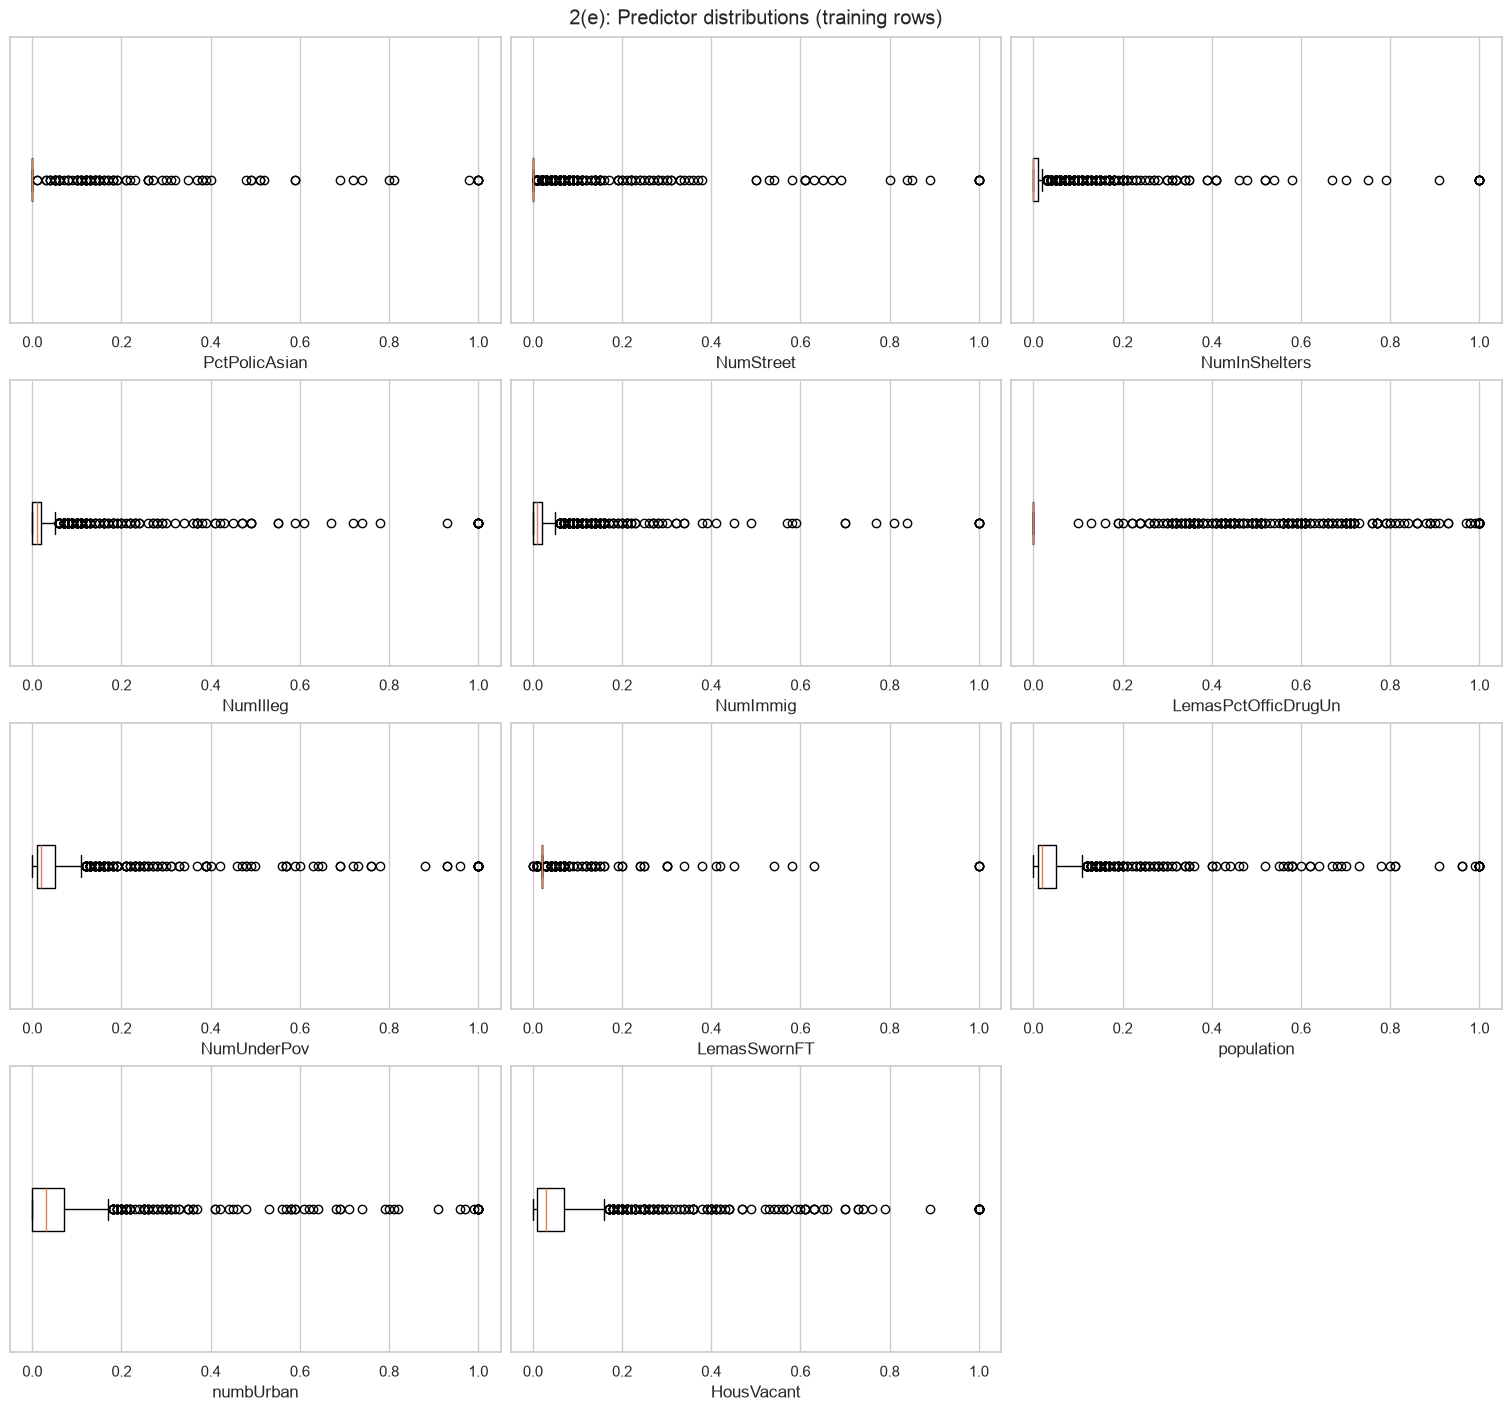

In [21]:
top=cv_table.loc[cv_table['CV'].notna(),'Feature'].head(int(np.floor(np.sqrt(128)))).tolist()
assert len(top)==11
table(cv_table.head(11),'top11_cv')
fig,axes=plt.subplots(4,3,figsize=(15,16),constrained_layout=True)
for ax,f in zip(axes.flat,top):
    ax.scatter(Xdesc[f],ytrain,s=8,alpha=.3); ax.set(xlabel=f,ylabel=target)
for ax in list(axes.flat)[len(top):]: ax.axis('off')
fig.suptitle('2(e): Highest-CV predictors versus target (training rows)')
figure(fig,'top11_scatter','Scatter plots for the 11 highest training CV predictors; y is always the crime target.')
fig,axes=plt.subplots(4,3,figsize=(15,14),constrained_layout=True)
for ax,f in zip(axes.flat,top):
    ax.boxplot(Xdesc[f],orientation='horizontal'); ax.set(xlabel=f,yticks=[])
for ax in list(axes.flat)[len(top):]: ax.axis('off')
fig.suptitle('2(e): Predictor distributions (training rows)')
figure(fig,'top11_boxplots','Individual horizontal box plots of the selected predictors.')

## 2(f) Ordinary least squares
OLS fits an intercept and all 122 imputed predictors by minimizing residual sum of squares. It has no tuned hyperparameter. Coefficients can be unstable under multicollinearity; the matrix rank and condition number below describe this concern. Main test error is MSE = mean((y-yhat)^2), with RMSE=sqrt(MSE) and R-squared also reported. All model test results are deliberately collected together after Question 2(j) has frozen every fitted model.

In [22]:
record_text('## 2(f) Ordinary least squares\nOLS fits an intercept and all 122 imputed predictors by minimizing residual sum of squares. It has no tuned hyperparameter. Coefficients can be unstable under multicollinearity; the matrix rank and condition number below describe this concern. Main test error is MSE = mean((y-yhat)^2), with RMSE=sqrt(MSE) and R-squared also reported. All model test results are deliberately collected together after Question 2(j) has frozen every fitted model.')

In [23]:
models={}; searches={}; selected={}; tuning_rows=[]
models['OLS']=make_pipe(LinearRegression()).fit(Xtrain,ytrain)
centered=Xdesc-Xdesc.mean()
singular=np.linalg.svd(centered.to_numpy(),compute_uv=False)
say(f'Centered training design rank = **{np.linalg.matrix_rank(centered)} / 122**; condition number = **{singular[0]/singular[-1]:.3g}**.')
def tune(name,pipe,param,values,expand=True):
    values=np.unique(np.asarray(values)).tolist()
    history=[]
    for attempt in range(5):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            search=GridSearchCV(pipe,{param:values},scoring='neg_mean_squared_error',cv=cv,n_jobs=1,error_score='raise',refit=True,return_train_score=False)
            search.fit(Xtrain,ytrain)
        convergence=[str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning)]
        if convergence:
            raise RuntimeError(f'{name}: convergence warnings; increase max_iter or revise solver before reporting results: '+convergence[0])
        other=[str(w.message) for w in caught]
        best=search.best_params_[param]
        history.append({'attempt':attempt+1,'min':min(values),'max':max(values),'count':len(values),'best':best,'warnings':other})
        at_low=best==min(values); at_high=best==max(values)
        if not expand or not (at_low or at_high): break
        if at_low and min(values)==0: break # natural nonnegative boundary
        if at_low:
            smallest=min(v for v in values if v>0)
            values=sorted(set(values+np.geomspace(smallest/100,smallest,9).tolist()))
        if at_high:
            largest=max(values)
            values=sorted(set(values+np.geomspace(largest,largest*100,9).tolist()))
    else: raise RuntimeError(f'{name}: unresolved grid boundary after expansion')
    results=pd.DataFrame(search.cv_results_)
    results['mean_CV_MSE']=-results['mean_test_score']
    results.to_csv(ROOT/'results'/f'cv_{name}.csv',index=False)
    models[name]=search.best_estimator_; searches[name]=search
    tuning_rows.append({'Model':name,'Parameter':param,'Selected':best,'CV MSE':-search.best_score_,'Grid min':min(values),'Grid max':max(values),'Candidates':len(values),'Convergence warnings':len(convergence)})
    (ROOT/'results'/f'search_audit_{name}.json').write_text(json.dumps(history,indent=2,default=float))
    say(f'**{name}:** {param} = **{best}**; five-fold CV MSE = **{-search.best_score_:.8f}**; final grid [{min(values)}, {max(values)}], {len(values)} candidates. Convergence warnings: **{len(convergence)}**. '+('The optimum is at the natural zero-penalty boundary, which cannot be extended downward.' if best==0 and min(values)==0 else 'The selected value is interior to the final search range.' if best not in [min(values),max(values)] else 'All admissible component counts are searched; a boundary here is a legitimate endpoint.'))
    return search

Centered training design rank = **121 / 122**; condition number = **3.51e+16**.

## 2(g) Ridge regression
A Pipeline applies median imputation and StandardScaler before Ridge. Scikit-learn Ridge minimizes ||y-Xb||^2 + alpha*||b||^2, with an unpenalized intercept. Thus its alpha is the assignment's lambda under this convention. A 49-point logarithmic grid from 1e-6 through 1e6 is searched using training-fold MSE; if an artificial endpoint wins, the range is expanded. Standardizing equalizes penalty treatment across features, despite their existing [0,1] normalization.

In [24]:
record_text("## 2(g) Ridge regression\nA Pipeline applies median imputation and StandardScaler before Ridge. Scikit-learn Ridge minimizes ||y-Xb||^2 + alpha*||b||^2, with an unpenalized intercept. Thus its alpha is the assignment's lambda under this convention. A 49-point logarithmic grid from 1e-6 through 1e6 is searched using training-fold MSE; if an artificial endpoint wins, the range is expanded. Standardizing equalizes penalty treatment across features, despite their existing [0,1] normalization.")

In [25]:
tune('Ridge',make_pipe(Ridge(solver='svd'),scale=True),'model__alpha',np.logspace(-6,6,49))

**Ridge:** model__alpha = **56.23413251903491**; five-fold CV MSE = **0.01914446**; final grid [1e-06, 1000000.0], 49 candidates. Convergence warnings: **0**. The selected value is interior to the final search range.

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lver='svd'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [1e-06, 1.778279410038923e-06, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 3, ...shape=(1196,)), ...), (array([ 0, ...shape=(1196,)), ...), ...]"
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.p

## 2(h) LASSO without and with standardization
Both models use median imputation inside CV. The first retains the original supplied normalized units; the second applies fold-fitted StandardScaler. Lasso minimizes ||y-Xb||^2/(2*n) + alpha*||b||_1 with an unpenalized intercept, so numerical alpha is not directly comparable with Ridge alpha. Each model searches 41 logarithmically spaced values from 1e-5 to 1e-1, expanding artificial boundaries if needed. A strict tolerance of 1e-7 and max_iter=200000 are used; convergence warnings cause execution to fail instead of being hidden. Selected variables have absolute fitted coefficient greater than 1e-10. Coefficients for the standardized fit are expressed per training standard deviation; original-unit equivalents are also exported.

In [26]:
record_text('## 2(h) LASSO without and with standardization\nBoth models use median imputation inside CV. The first retains the original supplied normalized units; the second applies fold-fitted StandardScaler. Lasso minimizes ||y-Xb||^2/(2*n) + alpha*||b||_1 with an unpenalized intercept, so numerical alpha is not directly comparable with Ridge alpha. Each model searches 41 logarithmically spaced values from 1e-5 to 1e-1, expanding artificial boundaries if needed. A strict tolerance of 1e-7 and max_iter=200000 are used; convergence warnings cause execution to fail instead of being hidden. Selected variables have absolute fitted coefficient greater than 1e-10. Coefficients for the standardized fit are expressed per training standard deviation; original-unit equivalents are also exported.')

In [27]:
for name,scale in [('LASSO_unscaled',False),('LASSO_scaled',True)]:
    tune(name,make_pipe(Lasso(max_iter=200000,tol=1e-7,selection='cyclic'),scale=scale),'model__alpha',np.logspace(-5,-1,41))
    coef=models[name].named_steps['model'].coef_
    mask=np.abs(coef)>1e-10
    selected[name]=Xtrain.columns[mask].tolist()
    original=coef/models[name].named_steps['scale'].scale_ if scale else coef
    coeffs=pd.DataFrame({'Feature':Xtrain.columns,'Fitted coefficient':coef,'Original-unit coefficient':original,'Selected':mask})
    coeffs.to_csv(ROOT/'results'/f'coefficients_{name}.csv',index=False)
    table(coeffs.loc[mask,['Feature','Fitted coefficient','Original-unit coefficient']].reset_index(drop=True),f'selected_{name}')
    fit=models[name].named_steps['model']
    say(f'**{name} selects {mask.sum()} variables:** '+', '.join(selected[name])+f'. Final solver iterations: {fit.n_iter_}; dual gap: {fit.dual_gap_:.3g}.')
say('Standardization changes the effective L1 penalty in original units: a unit change in a low-variance feature is treated differently after scaling. Hence the fitted supports and optimal penalties can differ. Correlated predictors may substitute for each other, so an excluded variable is not necessarily irrelevant. The test-error comparison follows in the frozen evaluation table.')

**LASSO_unscaled:** model__alpha = **0.0001**; five-fold CV MSE = **0.01899094**; final grid [1e-05, 0.1], 41 candidates. Convergence warnings: **0**. The selected value is interior to the final search range.

,Feature,Fitted coefficient,Original-unit coefficient
0,racepctblack,0.26880774,0.26880774
1,racePctAsian,-0.01723136,-0.01723136
2,agePct12t21,0.07472101,0.07472101
3,agePct12t29,-0.29105342,-0.29105342
4,agePct65up,0.00200299,0.00200299
5,pctUrban,0.04124881,0.04124881
6,pctWWage,-0.09227776,-0.09227776
7,pctWFarmSelf,0.02909083,0.02909083
8,pctWInvInc,-0.11136971,-0.11136971
9,pctWSocSec,0.06071021,0.06071021


**LASSO_unscaled selects 75 variables:** racepctblack, racePctAsian, agePct12t21, agePct12t29, agePct65up, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctBSorMore, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolicAsian, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, LemasPctPolicOnPatr, LemasGangUnitDeploy. Final solver iterations: 573; dual gap: 5.54e-09.

**LASSO_scaled:** model__alpha = **0.000630957344480193**; five-fold CV MSE = **0.01910257**; final grid [1e-05, 0.1], 41 candidates. Convergence warnings: **0**. The selected value is interior to the final search range.

,Feature,Fitted coefficient,Original-unit coefficient
0,racepctblack,0.06800526,0.26473137
1,racePctAsian,-0.00186313,-0.00892129
2,agePct12t21,0.01248646,0.08007205
3,agePct12t29,-0.04330397,-0.30218199
4,pctUrban,0.01713055,0.03842010
5,pctWWage,-0.01423891,-0.07831041
6,pctWFarmSelf,0.00484792,0.02377652
7,pctWInvInc,-0.02214387,-0.12229642
8,pctWSocSec,0.01040427,0.06066433
9,pctWPubAsst,0.00791543,0.03466475


**LASSO_scaled selects 76 variables:** racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctSameCity85, LemasSwFTFieldPerPop, LemasTotalReq, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctPolicAsian, OfficAssgnDrugUnits, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, LemasPctPolicOnPatr, LemasGangUnitDeploy. Final solver iterations: 546; dual gap: 4.74e-09.

Standardization changes the effective L1 penalty in original units: a unit change in a low-variance feature is treated differently after scaling. Hence the fitted supports and optimal penalties can differ. Correlated predictors may substitute for each other, so an excluded variable is not necessarily irrelevant. The test-error comparison follows in the frozen evaluation table.

## 2(i) Principal component regression (PCR)
The Pipeline is median imputation -> standardization -> full-SVD PCA -> ordinary least squares. M is selected by the same five training folds and validation MSE. All integer values 1 through 122 are searched, so neither endpoint is an artificial truncated search boundary. PCA directions, imputation medians and scaling statistics are refitted within each fold. PCA maximizes predictor variance, not association with the response; a high explained-variance fraction alone does not determine the best M.

In [28]:
record_text('## 2(i) Principal component regression (PCR)\nThe Pipeline is median imputation -> standardization -> full-SVD PCA -> ordinary least squares. M is selected by the same five training folds and validation MSE. All integer values 1 through 122 are searched, so neither endpoint is an artificial truncated search boundary. PCA directions, imputation medians and scaling statistics are refitted within each fold. PCA maximizes predictor variance, not association with the response; a high explained-variance fraction alone does not determine the best M.')

In [29]:
tune('PCR',make_pipe(LinearRegression(),scale=True,pca=True),'pca__n_components',np.arange(1,123),expand=False)
pcr=models['PCR'].named_steps['pca']
say(f'The selected {pcr.n_components_} components explain **{pcr.explained_variance_ratio_.sum():.4%}** of standardized training predictor variance.')

**PCR:** pca__n_components = **93**; five-fold CV MSE = **0.01944865**; final grid [1, 122], 122 candidates. Convergence warnings: **0**. The selected value is interior to the final search range.

The selected 93 components explain **99.7959%** of standardized training predictor variance.

## 2(j) L1-penalized boosting with XGBoost
Implementation assumption: interpret the allowed XGBoost option as **booster="gbtree"** with a CV-selected **reg_alpha**, an L1 penalty on scalar leaf weights. Standard tree leaves predict constants; they do not fit LASSO regressions at nodes. This differs from a literal tree with local multivariate L1 regressions. The standard gbtree implementation fulfills the explicit XGBoost option under this stated interpretation; no unsupported local-linear-tree claim is made. gblinear would fit a linear booster and would not be a boosting tree.

For a fixed tree structure, the regularizer includes reg_alpha*sum(|w_j|) + (reg_lambda/2)*sum(w_j^2). The L1 term can shrink leaf weights to zero and affects split gains. It is not direct coefficient selection over the original 122 features. See the official [XGBoost parameter documentation](https://xgboost.readthedocs.io/en/stable/parameter.html) and [boosted-tree introduction](https://xgboost.readthedocs.io/en/stable/tutorials/model.html).

The fixed, predeclared configuration uses squared-error loss, 400 trees, learning_rate=0.04, max_depth=3, min_child_weight=5, reg_lambda=1, subsample=1, colsample_bytree=1, gamma=0, hist trees, n_jobs=1 and seed 552. Only reg_alpha is tuned: zero plus 29 positive log-spaced candidates from 1e-5 through 1e2, expanding if necessary. Median imputation remains inside the Pipeline for consistent data handling. No test-set early stopping is used; other tree settings are fixed modeling assumptions, not claimed globally optimal.

In [30]:
record_text('## 2(j) L1-penalized boosting with XGBoost\nImplementation assumption: interpret the allowed XGBoost option as **booster="gbtree"** with a CV-selected **reg_alpha**, an L1 penalty on scalar leaf weights. Standard tree leaves predict constants; they do not fit LASSO regressions at nodes. This differs from a literal tree with local multivariate L1 regressions. The standard gbtree implementation fulfills the explicit XGBoost option under this stated interpretation; no unsupported local-linear-tree claim is made. gblinear would fit a linear booster and would not be a boosting tree.\n\nFor a fixed tree structure, the regularizer includes reg_alpha*sum(|w_j|) + (reg_lambda/2)*sum(w_j^2). The L1 term can shrink leaf weights to zero and affects split gains. It is not direct coefficient selection over the original 122 features. See the official [XGBoost parameter documentation](https://xgboost.readthedocs.io/en/stable/parameter.html) and [boosted-tree introduction](https://xgboost.readthedocs.io/en/stable/tutorials/model.html).\n\nThe fixed, predeclared configuration uses squared-error loss, 400 trees, learning_rate=0.04, max_depth=3, min_child_weight=5, reg_lambda=1, subsample=1, colsample_bytree=1, gamma=0, hist trees, n_jobs=1 and seed 552. Only reg_alpha is tuned: zero plus 29 positive log-spaced candidates from 1e-5 through 1e2, expanding if necessary. Median imputation remains inside the Pipeline for consistent data handling. No test-set early stopping is used; other tree settings are fixed modeling assumptions, not claimed globally optimal.')

**XGBoost:** model__reg_alpha = **0.00017782794100389227**; five-fold CV MSE = **0.01970332**; final grid [0.0, 100.0], 30 candidates. Convergence warnings: **0**. The selected value is interior to the final search range.

,Model,Parameter,Selected,CV MSE,Grid min,Grid max,Candidates,Convergence warnings
0,Ridge,model__alpha,56.23413252,0.01914446,0.000001,1000000.0,49,0
1,LASSO_unscaled,model__alpha,0.00010000,0.01899094,0.000010,0.1,41,0
2,LASSO_scaled,model__alpha,0.00063096,0.01910257,0.000010,0.1,41,0
3,PCR,pca__n_components,93.00000000,0.01944865,1.000000,122.0,122,0
4,XGBoost,model__reg_alpha,0.00017783,0.01970332,0.000000,100.0,30,0


,Model,Selected parameter,CV MSE,Test MSE,Test RMSE,Test R2,Selected variables
0,OLS,"{""method"": ""least squares""}",NaN,0.01796622,0.13403811,0.62220372,N/A
1,Ridge,"{""model__alpha"": 56.23413251903491}",0.01914446,0.01747522,0.13219389,0.63252837,N/A
2,LASSO_unscaled,"{""model__alpha"": 0.0001}",0.01899094,0.01765779,0.13288261,0.62868938,75
3,LASSO_scaled,"{""model__alpha"": 0.000630957344480193}",0.01910257,0.01772176,0.13312311,0.62734410,76
4,PCR,"{""pca__n_components"": 93}",0.01944865,0.01826425,0.13514528,0.61593669,N/A
5,XGBoost,"{""model__reg_alpha"": 0.00017782794100389227}",0.01970332,0.01621407,0.12733449,0.65904803,N/A


**OLS: test MSE = 0.01796622; RMSE = 0.13403811; R-squared = 0.622204.**

**Ridge: test MSE = 0.01747522; RMSE = 0.13219389; R-squared = 0.632528.**

**LASSO_unscaled: test MSE = 0.01765779; RMSE = 0.13288261; R-squared = 0.628689.**

**LASSO_scaled: test MSE = 0.01772176; RMSE = 0.13312311; R-squared = 0.627344.**

**PCR: test MSE = 0.01826425; RMSE = 0.13514528; R-squared = 0.615937.**

**XGBoost: test MSE = 0.01621407; RMSE = 0.12733449; R-squared = 0.659048.**

Standardized LASSO selected **76** variables versus **75** without standardization. Its test MSE is **0.00006398 higher**. This is a final held-out comparison, not a reason to retune. Lowest observed test MSE among the prespecified fits: **XGBoost**. This descriptive ranking on one fixed split does not establish a statistically reliable winner or estimate the performance of a newly selected model.

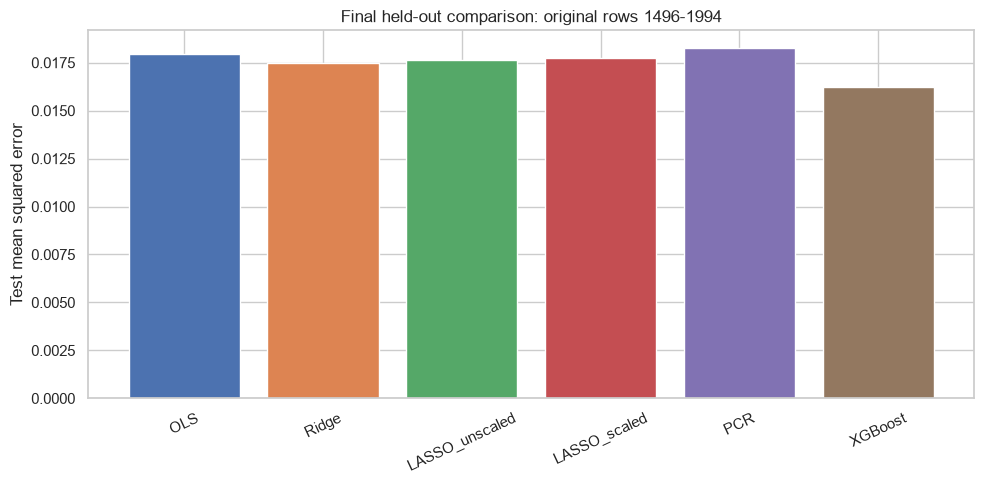

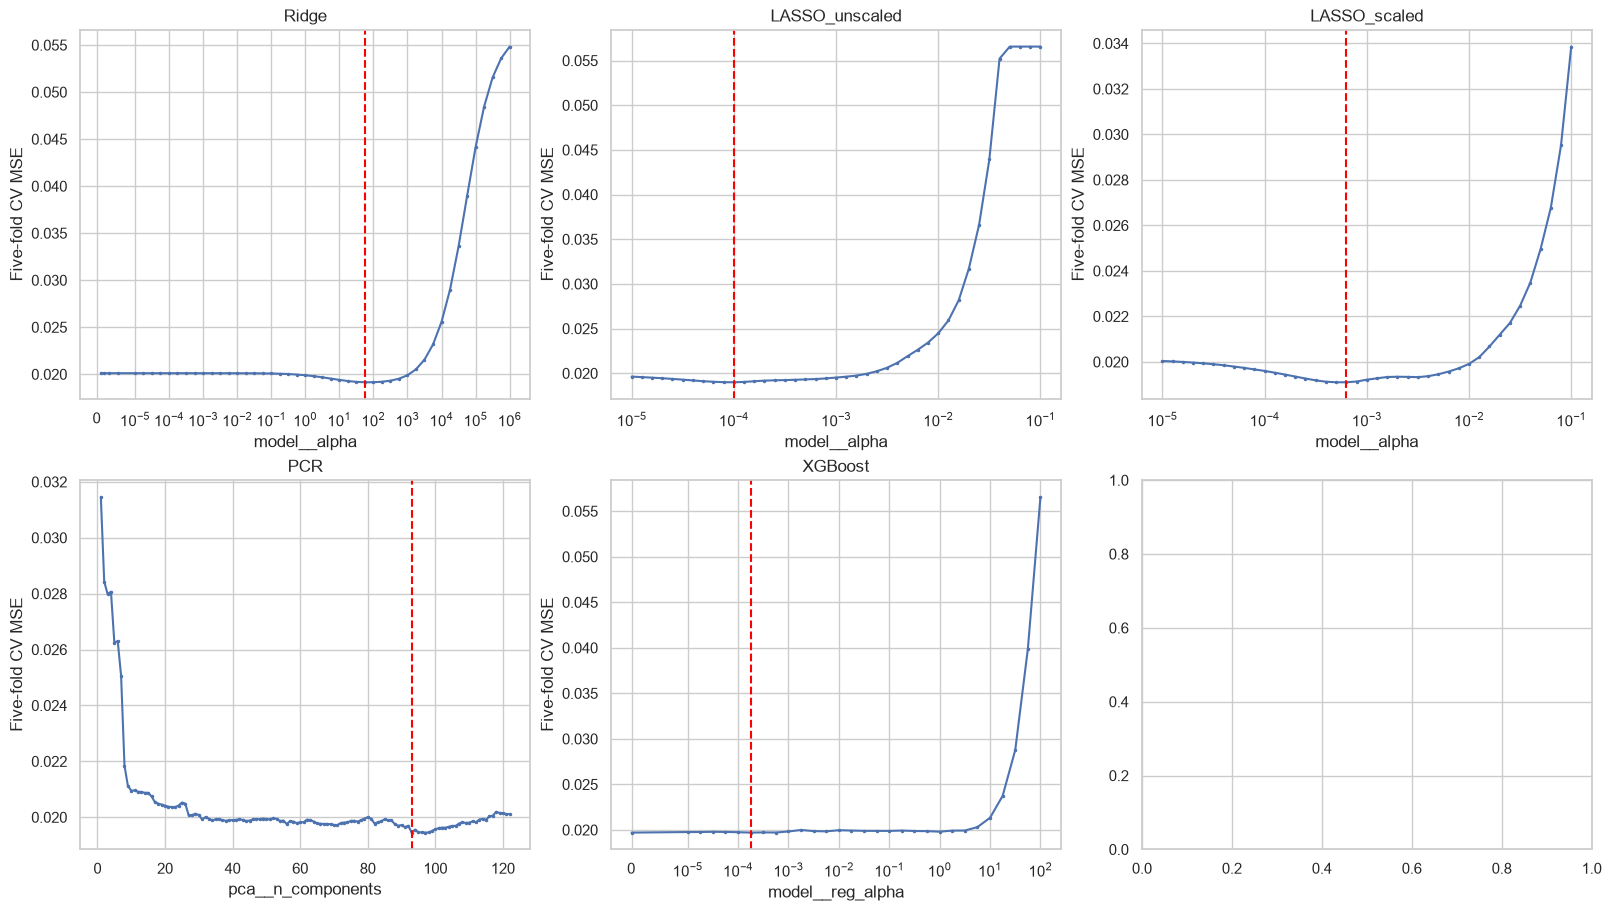

In [31]:
xgb=XGBRegressor(booster='gbtree',objective='reg:squarederror',n_estimators=400,
    learning_rate=.04,max_depth=3,min_child_weight=5,reg_lambda=1,subsample=1,
    colsample_bytree=1,gamma=0,tree_method='hist',random_state=SEED,n_jobs=1,verbosity=0)
tune('XGBoost',make_pipe(xgb),'model__reg_alpha',np.r_[0,np.logspace(-5,2,29)])
table(pd.DataFrame(tuning_rows),'tuning_summary')
# Freeze the six final fitted pipelines before any test prediction.
assert len(models)==6
frozen_names=tuple(models)
rows=[]
for name in frozen_names:
    prediction=models[name].predict(Xtest)
    mse=mean_squared_error(ytest,prediction)
    params=searches[name].best_params_ if name in searches else {'method':'least squares'}
    rows.append({'Model':name,'Selected parameter':json.dumps(params),'CV MSE':-searches[name].best_score_ if name in searches else np.nan,'Test MSE':mse,'Test RMSE':np.sqrt(mse),'Test R2':r2_score(ytest,prediction),'Selected variables':len(selected[name]) if name in selected else 'N/A'})
    pd.DataFrame({'Original row (1-based)':Xtest.index+1,'Observed':ytest,'Predicted':prediction}).to_csv(ROOT/'results'/f'predictions_{name}.csv',index=False)
metrics=pd.DataFrame(rows)
table(metrics,'model_comparison')
for row in rows:
    say(f'**{row["Model"]}: test MSE = {row["Test MSE"]:.8f}; RMSE = {row["Test RMSE"]:.8f}; R-squared = {row["Test R2"]:.6f}.**')
a=metrics.set_index('Model')
delta=a.loc['LASSO_scaled','Test MSE']-a.loc['LASSO_unscaled','Test MSE']
say(f'Standardized LASSO selected **{len(selected["LASSO_scaled"])}** variables versus **{len(selected["LASSO_unscaled"])}** without standardization. Its test MSE is **{abs(delta):.8f} {"lower" if delta<0 else "higher"}**. This is a final held-out comparison, not a reason to retune. Lowest observed test MSE among the prespecified fits: **{metrics.loc[metrics["Test MSE"].idxmin(),"Model"]}**. This descriptive ranking on one fixed split does not establish a statistically reliable winner or estimate the performance of a newly selected model.')
fig,ax=plt.subplots(figsize=(10,5)); ax.bar(metrics['Model'],metrics['Test MSE'],color=sns.color_palette('deep',6)); ax.set(ylabel='Test mean squared error',title='Final held-out comparison: original rows 1496-1994'); ax.tick_params(axis='x',rotation=25); fig.tight_layout(); figure(fig,'model_test_mse','One final test evaluation for each frozen model. No test-based tuning.')
# CV plots are based on training folds, independent of held-out outcomes.
fig,axes=plt.subplots(2,3,figsize=(16,9),constrained_layout=True)
for ax,(name,search) in zip(axes.flat,searches.items()):
    param=list(search.best_params_)[0]
    xx=np.array([float(p[param]) for p in search.cv_results_['params']]); yy=-search.cv_results_['mean_test_score']
    order=np.argsort(xx); ax.plot(xx[order],yy[order],'.-',ms=3)
    if name!='PCR': ax.set_xscale('symlog',linthresh=1e-5)
    ax.axvline(float(search.best_params_[param]),color='red',ls='--'); ax.set(title=name,xlabel=param,ylabel='Five-fold CV MSE')
figure(fig,'cv_curves','Training-only hyperparameter selection curves. Dashed lines mark selected settings.')

## Reproducibility, validation and limitations
The notebook must run from the project root. All input and output paths are relative. Pinned dependencies, raw data hashes, fold assignments, full search results, LASSO coefficient tables, rules and test predictions are included. Every code cell is executed in order by a fresh Jupyter kernel using scripts/run_notebook.py. scripts/make_report.py creates the English PDF from the same recorded narrative, tables and figures, so the report is tied to computed outputs.

The original nonrandom external split may have distribution shifts; shuffled internal CV assumes exchangeability within the training portion. It does not account for possible geographic or social dependence. Median filling of heavily missing police variables is an information limitation, not a claim that missingness is ignorable. The 11 highest-CV features are not a formal inferential screen. Model rankings are specific to this split and stated configurations. Hyperparameter searches resolve grid endpoints, but do not guarantee a continuous global optimum.

No additional course submission naming, upload, repository, or packaging rules appear in the supplied homework PDF. Only the supplied instructions are asserted here.

In [32]:
record_text('## Reproducibility, validation and limitations\nThe notebook must run from the project root. All input and output paths are relative. Pinned dependencies, raw data hashes, fold assignments, full search results, LASSO coefficient tables, rules and test predictions are included. Every code cell is executed in order by a fresh Jupyter kernel using scripts/run_notebook.py. scripts/make_report.py creates the English PDF from the same recorded narrative, tables and figures, so the report is tied to computed outputs.\n\nThe original nonrandom external split may have distribution shifts; shuffled internal CV assumes exchangeability within the training portion. It does not account for possible geographic or social dependence. Median filling of heavily missing police variables is an information limitation, not a claim that missingness is ignorable. The 11 highest-CV features are not a formal inferential screen. Model rankings are specific to this split and stated configurations. Hyperparameter searches resolve grid endpoints, but do not guarantee a continuous global optimum.\n\nNo additional course submission naming, upload, repository, or packaging rules appear in the supplied homework PDF. Only the supplied instructions are asserted here.')

In [33]:
checklist=[('1(a)','120 rows, six features, two diagnoses; local data parsed'),('1(b)','Full-data fitted tree, complete plot and label mapping'),('1(c)','Every full-tree root-to-leaf rule; exact prediction agreement'),('1(d)','Cost-complexity CV, complexity/performance comparison, selected tree and all rules'),('2(a)','1994 x 128; original first 1495/last 499 split'),('2(b)','Five identifiers removed; fold-local median imputation; 122 predictors retained'),('2(c)','Full predictor correlation matrix plus readable panels'),('2(d)','All predictor CVs; ddof=1; training-only scope and edge cases'),('2(e)','Exactly 11 features; scatter and box plots; significance answer'),('2(f)','OLS fitted; test MSE, RMSE, R2'),('2(g)','Ridge CV alpha; test metrics'),('2(h)','Both LASSOs; CV alpha, support names/counts, convergence, comparison'),('2(i)','PCA plus OLS; all M searched by fold-local CV; test metrics'),('2(j)','gbtree/reg_alpha CV; explicit interpretation; test metrics')]
assert all(np.isfinite(metrics[c]).all() for c in ['Test MSE','Test RMSE','Test R2'])
assert all(p.named_steps['impute'].n_features_in_==122 for p in models.values())
assert len(full_rules)==full.get_n_leaves() and len(pruned_rules)==pruned.get_n_leaves()
assert set(top).issubset(set(Xtrain.columns)) and target not in Xtrain.columns
assert all(len(set(tr)&set(va))==0 for tr,va in cv)
table(pd.DataFrame([{'Item':q,'Verified requirement':s,'Status':'Complete'} for q,s in checklist]),'completion_checklist')
say('**Outstanding assignment items: none.** A literal local-LASSO model tree is not claimed; the documented standard-XGBoost interpretation of 2(j) is used. Unprovided course submission rules cannot be verified. Final PDF layout and fresh-kernel execution are additionally checked by the packaging workflow.')
(ROOT/'results'/'report_content.json').write_text(json.dumps(report,indent=2,allow_nan=False))
(ROOT/'results'/'execution_checks.json').write_text(json.dumps({'all_assignment_items_complete':True,'rows_acute':120,'features_acute':6,'labels_acute':2,'communities_shape':list(communities.shape),'train_rows':len(Xtrain),'test_rows':len(Xtest),'predictors':122,'top_cv_features':top,'rule_agreement_checked':True,'test_evaluations_per_model':1,'convergence_warnings':0,'seed':SEED},indent=2))
print('All computational checks passed; report content and reproducibility artifacts written.')

,Item,Verified requirement,Status
0,1(a),"120 rows, six features, two diagnoses; local data parsed",Complete
1,1(b),"Full-data fitted tree, complete plot and label mapping",Complete
2,1(c),Every full-tree root-to-leaf rule; exact prediction agreement,Complete
3,1(d),"Cost-complexity CV, complexity/performance comparison, selected tree and all rules",Complete
4,2(a),1994 x 128; original first 1495/last 499 split,Complete
5,2(b),Five identifiers removed; fold-local median imputation; 122 predictors retained,Complete
6,2(c),Full predictor correlation matrix plus readable panels,Complete
7,2(d),All predictor CVs; ddof=1; training-only scope and edge cases,Complete
8,2(e),Exactly 11 features; scatter and box plots; significance answer,Complete
9,2(f),"OLS fitted; test MSE, RMSE, R2",Complete


**Outstanding assignment items: none.** A literal local-LASSO model tree is not claimed; the documented standard-XGBoost interpretation of 2(j) is used. Unprovided course submission rules cannot be verified. Final PDF layout and fresh-kernel execution are additionally checked by the packaging workflow.

All computational checks passed; report content and reproducibility artifacts written.


## References
- Supplied Homework5.pdf, Questions 1-2 and footnotes 1-5.
- Supplied diagnosis.names and diagnosis.data. J. Czerniak and H. Zarzycki, Application of rough sets in the presumptive diagnosis of urinary system diseases, ACS 2002, 2003, pp. 41-51.
- Supplied communities.names and communities.data, UCI Machine Learning Repository; source data: US Census 1990, LEMAS 1990, FBI Crime in the United States 1995. M. A. Redmond and A. Baveja, A Data-Driven Software Tool for Enabling Cooperative Information Sharing Among Police Departments, European Journal of Operational Research 141 (2002), 660-678.
- Matthew Mayo, Simplifying Decision Tree Interpretability with Python & Scikit-learn, KDnuggets (2017), supplied PDF. The path traversal here is a fresh implementation with label decoding and prediction assertions.
- [Scikit-learn Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) and [Lasso documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html), for objective conventions.
- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html) and [boosted-tree introduction](https://xgboost.readthedocs.io/en/stable/tutorials/model.html), for booster and leaf-weight regularization semantics.

In [34]:
record_text('## References\n- Supplied Homework5.pdf, Questions 1-2 and footnotes 1-5.\n- Supplied diagnosis.names and diagnosis.data. J. Czerniak and H. Zarzycki, Application of rough sets in the presumptive diagnosis of urinary system diseases, ACS 2002, 2003, pp. 41-51.\n- Supplied communities.names and communities.data, UCI Machine Learning Repository; source data: US Census 1990, LEMAS 1990, FBI Crime in the United States 1995. M. A. Redmond and A. Baveja, A Data-Driven Software Tool for Enabling Cooperative Information Sharing Among Police Departments, European Journal of Operational Research 141 (2002), 660-678.\n- Matthew Mayo, Simplifying Decision Tree Interpretability with Python & Scikit-learn, KDnuggets (2017), supplied PDF. The path traversal here is a fresh implementation with label decoding and prediction assertions.\n- [Scikit-learn Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) and [Lasso documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html), for objective conventions.\n- [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html) and [boosted-tree introduction](https://xgboost.readthedocs.io/en/stable/tutorials/model.html), for booster and leaf-weight regularization semantics.')

In [35]:
(ROOT/'results'/'report_content.json').write_text(json.dumps(report,indent=2,allow_nan=False))
print('Report content finalized.')

Report content finalized.
